# Revision experiments — *Beyond a Single Benchmark* (MJCS-D-26-00034)

One clean pipeline that answers every editor comment. It runs unchanged on **Google Colab**, **Kaggle** or a local PC
(the platform is detected automatically).

| Comment | What this notebook does | Main outputs |
|---|---|---|
| #2 PhiUSIIL shortcut | URL canonicalisation (scheme, `www.`, trailing `/` removed); label-conflict and duplicate removal on the canonical URL; feature-removal ladder; domain-disjoint CV; legitimate login / deep-link tests; external URLs of unseen domains; URL-shape rules on the **same** held-out records | `tab_shortcut`, `tab_deeplink`, `tab_external`, `fig_shortcut_ladder`, `fig_deeplink_fpr`, `fig_external_roc`, `fig_shap_phiusiil` |
| #3 Test-set isolation | Settings fixed in advance; learning curves on an inner **train/validation** split only | `fig_lc_*` |
| #4 Statistics | 5-fold CV × seeds **42, 44** (10 paired folds), domain-grouped where possible; mean ± SD; corrected paired t-test, McNemar, domain-cluster bootstrap, Holm; Friedman/Nemenyi as descriptive | `tab_main`, `tab_paired`, `fig_forest_paired`, `fig_cd_diagram`, `fig_cv_boxplots` |
| #5 Deployment time | Batch vs single-URL end-to-end time; feature-availability counts; URL-only vs full features on all datasets | `tab_latency`, `tab_availability*`, `fig_latency`, `fig_availability` |
| #6 Reproducibility | Versions, config, SHA-256, retained row IDs, fold files; random-split domain overlap; random vs grouped scores | `repro/`, `tab_overlap`, `tab_split_effect`, `fig_overlap`, `fig_split_effect` |

Every metric table reports **Accuracy, Precision, Recall, F1, F2, ROC-AUC, PR-AUC, MCC, Balanced accuracy, FPR, FNR,
training time and inference time** (mean ± SD over 10 folds). All fold-level numbers are also saved as CSV.

**How to run on Kaggle**
1. `+ Add Input` → attach the four CSV files as a dataset (any names listed in the CONFIG cell work; sub-folders are searched).
2. Optional: also attach `Phishing_Detection_External_Evaluation_Dataset_1000_URLs.csv` (extra external test set).
3. To reuse the earlier run: attach its `revision_results` folder (it must contain `ckpt/`). Finished folds are copied and skipped, so only the new Experiment 4 runs (≈1.5–2.5 h). Without it the full run takes ≈4–5 h.
4. Notebook settings: **Internet ON** (needed for `pip install tldextract`), Accelerator: None (CPU is enough).
5. Click **Save Version → Save & Run All (Commit)**. The run continues in the background even if you close the browser.
6. Open the saved version → **Output** tab → download `revision_results/revision_outputs.zip`; copy its `tables/` and `figures/` into Overleaf.

In [1]:
# ===================== 1. Setup =====================
import os, sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input")
PLATFORM = "Colab" if IN_COLAB else ("Kaggle" if IN_KAGGLE else "local")
if IN_COLAB or IN_KAGGLE:
    # tldextract is not pre-installed (Kaggle: turn "Internet" ON in the notebook settings for this line)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tldextract"], check=False)
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
print("Platform:", PLATFORM)

import re, json, time, math, glob, pickle, hashlib, platform, unicodedata, warnings, zipfile
from functools import lru_cache
from collections import OrderedDict
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
if PLATFORM == "local":
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
                             average_precision_score, matthews_corrcoef, confusion_matrix, roc_curve,
                             precision_recall_curve)
warnings.filterwarnings("ignore")

ALLOW_STANDIN = os.environ.get("ALLOW_STANDIN", "0") == "1"   # local smoke test only, never in Colab
try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except ImportError:
    HAVE_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAVE_LGBM = True
except ImportError:
    HAVE_LGBM = False
if not (HAVE_XGB and HAVE_LGBM):
    if not ALLOW_STANDIN:
        raise ImportError("xgboost and lightgbm are required: pip install xgboost lightgbm")
    from sklearn.ensemble import HistGradientBoostingClassifier
    print("WARNING: xgboost/lightgbm not installed -> HistGradientBoosting stand-ins (smoke test only).")
try:
    import tldextract
    _TLD = tldextract.TLDExtract(suffix_list_urls=())   # bundled Public Suffix List snapshot -> deterministic, offline
    HAVE_TLDEXTRACT = True
except ImportError:
    HAVE_TLDEXTRACT = False
    if PLATFORM != "local":
        raise ImportError("tldextract could not be installed. Kaggle: Settings -> Internet ON, then run again.")
    print("WARNING: tldextract not installed -> simplified suffix rules (smoke test only).")

Platform: Kaggle


In [ ]:
# ===================== 2. CONFIG =====================
# The four CSV files are found automatically (any sub-folder) under these roots. Accepted file names include the
# names used on Kaggle / Mendeley, so the files do not need to be renamed.
DEFAULT_ROOT = {"Colab": "/content/drive/MyDrive", "Kaggle": "/kaggle/input", "local": "."}[PLATFORM]
DATA_DIR = os.environ.get("DATA_DIR", DEFAULT_ROOT)
FILES = {
    "PhiUSIIL": ["PhiUSIIL_Phishing_URL_Dataset.csv"],
    "WebPage":  ["Web_Page_Phishing_Detection.csv", "dataset_phishing.csv", "dataset_B_05_2020.csv"],
    "PhishWeb": ["Phishing_Websites_Dataset.csv", "Phishing_Websites_Dataset_1.csv", "dataset_full.csv"],
    "Tan":      ["Phishing_Legitimate_full.csv"],
}

# Kaggle dataset folders (uploaded under /kaggle/input/...). If the CSV inside has any
# other name, the single .csv file of the matching folder is used.
FOLDER_HINTS = {
    "PhiUSIIL": ["phiusiil-phishing-url-dataset", "phiusiil"],
    "WebPage":  ["web-page-phishing-detection", "web-page-phishing"],
    "PhishWeb": ["phishing-websites-dataset", "phishing-websites"],
    "Tan":      ["phishing-legitimate-full", "phishing-legitimate"],
}

def find_file(key, root):
    names = FILES[key]
    for n in names:                                       # 1) exact file name, directly or in any sub-folder
        p = os.path.join(root, n)
        if os.path.exists(p):
            return p
        hits = sorted(glob.glob(os.path.join(root, "**", n), recursive=True))
        if hits:
            return hits[0]
    for hint in FOLDER_HINTS[key]:                        # 2) the CSV inside the matching dataset folder
        for folder in sorted(glob.glob(os.path.join(root, "**", "*" + hint + "*"), recursive=True)):
            if not os.path.isdir(folder):
                continue
            csvs = sorted(glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True))
            if csvs:
                return csvs[0]
    raise FileNotFoundError(f"{key}: none of {names} and no folder like {FOLDER_HINTS[key]} under {root}")

PATHS = {k: find_file(k, DATA_DIR) for k in FILES}
# Optional third URL source used ONLY as an external test set (columns: URL, Results with 1 = phishing).
OPTIONAL_FILES = {"Ext1000": ["Phishing_Detection_External_Evaluation_Dataset_1000_URLs.csv"]}
FOLDER_HINTS["Ext1000"] = ["phishing-detection-external-evaluation-dataset-100", "external-evaluation", "phishing-detection-external"]
for _k, _v in OPTIONAL_FILES.items():
    FILES[_k] = _v
    try:
        PATHS[_k] = find_file(_k, DATA_DIR)
    except FileNotFoundError:
        FILES.pop(_k); print(f"optional file {_k} not found -> skipped")
print(json.dumps(PATHS, indent=1))
DS_LABEL = {"PhiUSIIL": "PhiUSIIL", "WebPage": "Web Page Phishing", "PhishWeb": "Phishing Websites", "Tan": "Phish. Legit. Full (Tan)"}
OUT_DIR = os.environ.get("OUT_DIR", {"Colab": "/content/drive/MyDrive/revision_results",
                                     "Kaggle": "/kaggle/working/revision_results"}.get(PLATFORM, "revision_results"))

SEEDS = [42, 44]            # every CV repetition and every model uses these seeds
N_FOLDS = 5                 # 5-fold CV x 2 seeds = 10 paired folds per dataset
SVM_MAX_TRAIN = 20000       # RBF-SVM is trained on a stratified sample of at most this many rows per fold
N_BOOT = 1000               # paired (domain-cluster) bootstrap resamples
N_DEEPLINK = 3000           # legitimate test URLs per fold used to build deep-link / login variants
N_LATENCY = 1000            # URLs timed one by one for end-to-end latency
MEASURE_NETWORK = False     # True = also time DNS + HTTPS fetch for a few LEGITIMATE homepages (needs internet)
MODELS = ["RF", "SVM", "DT", "XGBoost", "LightGBM"]
RUN = {"audit": True, "main": True, "split_effect": True, "shortcut": True, "availability": True,
       "learning_curves": True, "latency": True, "stats": True}
if os.environ.get("RUN_ONLY"):                      # e.g. RUN_ONLY=audit (local use; leave unset in Colab)
    RUN = {k: (k in os.environ["RUN_ONLY"].split(",")) for k in RUN}

QUICK = os.environ.get("QUICK", "0") == "1"   # local smoke test: subsample every dataset
QUICK_N = int(os.environ.get("QUICK_N", "4000"))

for sub in ["ckpt", "tables", "figures", "repro"]:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
# Resume: if checkpoints of an earlier run are attached as input (e.g. the old revision_results folder or zip
# uploaded as a Kaggle dataset), copy them so that only new experiments are computed.
import shutil as _sh
for _p in glob.glob(os.path.join(DATA_DIR, "**", "ckpt", "*.pkl"), recursive=True):
    _dst = os.path.join(OUT_DIR, "ckpt", os.path.basename(_p))
    if os.path.abspath(_p) != os.path.abspath(_dst) and not os.path.exists(_dst):
        _sh.copy(_p, _dst)
print("checkpoints available:", len(glob.glob(os.path.join(OUT_DIR, "ckpt", "*.pkl"))))
TAB = lambda f: os.path.join(OUT_DIR, "tables", f)
FIG = lambda f: os.path.join(OUT_DIR, "figures", f)
REP = lambda f: os.path.join(OUT_DIR, "repro", f)

CONFIG = dict(SEEDS=SEEDS, N_FOLDS=N_FOLDS, SVM_MAX_TRAIN=SVM_MAX_TRAIN, NGRAM="char 3-5 TF-IDF, min_df 3, 100k; chi2 top-2000 for non-LR models; RF/DT <= 60k rows", N_BOOT=N_BOOT, N_DEEPLINK=N_DEEPLINK,
              MODELS=MODELS, QUICK=QUICK, platform=PLATFORM, model_settings={
                  "RF": "n_estimators=200, Gini, max_features=sqrt, no depth limit",
                  "SVM": "StandardScaler + RBF, C=1, gamma=scale, decision_function scores, <= SVM_MAX_TRAIN rows",
                  "DT": "Gini, no depth limit",
                  "XGBoost": "n_estimators=300, library defaults, eval_metric=logloss",
                  "LightGBM": "n_estimators=300, library defaults"},
              note="All settings fixed before any experiment; no setting was chosen on test folds.")
json.dump(CONFIG, open(REP("config.json"), "w"), indent=2)

In [3]:
# ===================== 3. URL utilities (canonicalisation, registrable domain, lexical features) ==========
_SCHEME = re.compile(r"^[a-zA-Z][a-zA-Z0-9+.\-]*://")
_FALLBACK_2LD = {"co.uk", "org.uk", "ac.uk", "gov.uk", "com.au", "net.au", "org.au", "co.jp", "co.in", "co.kr",
                 "com.br", "com.cn", "com.tr", "co.za", "com.mx", "com.ar", "co.id", "com.sg", "com.my", "co.nz",
                 "blogspot.com", "github.io", "herokuapp.com", "000webhostapp.com", "firebaseapp.com", "web.app"}

def canonicalize(url):
    """Reference normalisation + removal of the three PhiUSIIL surface artefacts (scheme, leading www., trailing /)."""
    u = unicodedata.normalize("NFKC", str(url)).strip()
    u = re.sub(r"[\x00-\x20\x7f]", "", u)
    u = _SCHEME.sub("", u)
    m = re.match(r"([^/?#]*)(.*)", u)
    host, rest = m.group(1).lower().rstrip("."), m.group(2)
    if host.startswith("www."):
        host = host[4:]
    if rest == "/":
        rest = ""
    elif rest.endswith("/") and "?" not in rest and "#" not in rest:
        rest = rest.rstrip("/")
    return host + rest

def split_canon(c):
    m = re.match(r"([^/?#]*)(.*)", c)
    host, rest = m.group(1), m.group(2)
    userinfo = "@" in host
    hn = host.rsplit("@", 1)[-1]
    port = bool(re.search(r":\d+$", hn))
    hn = re.sub(r":\d+$", "", hn)
    return hn, rest, userinfo, port

_IP = re.compile(r"^\d{1,3}(\.\d{1,3}){3}$")

@lru_cache(maxsize=None)
def reg_parts(hn):
    """Return (registrable_domain, suffix). IP hosts are their own registrable domain."""
    if not hn or _IP.match(hn):
        return hn, ""
    if HAVE_TLDEXTRACT:
        e = _TLD(hn)
        rd = getattr(e, "top_domain_under_public_suffix", None) or getattr(e, "registered_domain", "")
        return (rd or hn), e.suffix
    labels = hn.split(".")
    if len(labels) >= 3 and ".".join(labels[-2:]) in _FALLBACK_2LD:
        return ".".join(labels[-3:]), ".".join(labels[-2:])
    return ".".join(labels[-2:]), labels[-1]

def registrable_domain(url):
    return reg_parts(split_canon(canonicalize(url))[0])[0]

SENSITIVE = ("login", "signin", "sign-in", "logon", "verify", "verif", "secure", "account", "update", "confirm",
             "password", "passwd", "bank", "webscr", "auth", "wallet", "billing", "support", "unlock", "recover")
FILE_EXT = re.compile(r"\.(php|html?|aspx?|jsp|cgi|exe|zip|js)$")

def _entropy(s):
    if not s:
        return 0.0
    _, c = np.unique(list(s), return_counts=True)
    p = c / c.sum()
    return float(-(p * np.log2(p)).sum())

def url_features(c):
    """Lexical features of a CANONICAL URL. No network, no page content, no scheme / www information."""
    hn, rest, userinfo, port = split_canon(c)
    rd, suffix = reg_parts(hn)
    sub = hn[: -len(rd)].rstrip(".") if (rd and hn.endswith(rd) and hn != rd) else ""
    path, query = (rest.split("?", 1) + [""])[:2] if "?" in rest else (rest, "")
    path = path.split("#", 1)[0]
    low_host, low_rest = hn.lower(), rest.lower()
    digits = sum(ch.isdigit() for ch in c)
    special = sum((not ch.isalnum()) and ch not in "./" for ch in c)
    tokens = re.split(r"[./\-_?=&:]", c)
    return {
        # ---- host part (registrable domain + subdomain) ----
        "h_len": len(hn), "h_regdom_len": len(rd), "h_sub_len": len(sub),
        "h_sub_labels": 0 if not sub else sub.count(".") + 1, "h_dots": hn.count("."), "h_hyphens": hn.count("-"),
        "h_digits": sum(ch.isdigit() for ch in hn), "h_entropy": _entropy(hn), "h_is_ip": int(bool(_IP.match(hn))),
        "h_port": int(port), "h_userinfo": int(userinfo), "h_punycode": int("xn--" in hn), "h_tld_len": len(suffix),
        "h_sens_words": sum(w in low_host for w in SENSITIVE),
        # ---- whole URL / path / query ----
        "u_len": len(c), "u_digits": digits, "u_digit_ratio": digits / max(len(c), 1), "u_special": special,
        "u_hyphens": c.count("-"), "u_underscores": c.count("_"), "u_at": c.count("@"), "u_pct": c.count("%"),
        "u_tilde": c.count("~"), "u_longest_token": max((len(t) for t in tokens), default=0),
        "p_len": len(path), "p_depth": path.count("/"), "p_has_path": int(len(rest) > 0),
        "p_file_ext": int(bool(FILE_EXT.search(path.lower()))), "p_sens_words": sum(w in low_rest for w in SENSITIVE),
        "p_http_inside": int("http" in low_rest), "p_dslash": int("//" in rest),
        "q_len": len(query), "q_params": (query.count("&") + 1) if query else 0, "q_eq": query.count("="),
    }

LEX_ALL = list(url_features("a.example.com/x?y=1").keys())
LEX_HOST = [f for f in LEX_ALL if f.startswith("h_")]

def lex_frame(canon_series):
    return pd.DataFrame([url_features(c) for c in canon_series], index=canon_series.index).astype("float32")

def rule_raw_shape(raw_urls):
    """Original one-line rule: legitimate only if the RAW URL is a plain https://www. homepage. Returns 1=phishing."""
    return (~pd.Series(raw_urls).astype(str).str.match(r"^https://www\.[^/?#]+/?$")).astype(int).values

def rule_canon_homepage(canon_urls):
    """Residual rule after canonicalisation: legitimate only if nothing follows the host. Returns 1=phishing."""
    return np.array([int(len(split_canon(c)[1]) > 0) for c in canon_urls])

def sha256(path, block=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(block), b""):
            h.update(b)
    return h.hexdigest()

In [4]:
# ===================== 4. Load + clean the four datasets =====================
PHI_URL = ["URLLength", "DomainLength", "IsDomainIP", "URLSimilarityIndex", "CharContinuationRate", "TLDLegitimateProb",
           "URLCharProb", "TLDLength", "NoOfSubDomain", "HasObfuscation", "NoOfObfuscatedChar", "ObfuscationRatio",
           "NoOfLettersInURL", "LetterRatioInURL", "NoOfDegitsInURL", "DegitRatioInURL", "NoOfEqualsInURL",
           "NoOfQMarkInURL", "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL", "SpacialCharRatioInURL", "IsHTTPS"]
PHI_REFLIST = ["URLSimilarityIndex", "TLDLegitimateProb", "URLCharProb"]          # need a reference URL list/corpus
PW_EXTERNAL = ["time_response", "domain_spf", "asn_ip", "time_domain_activation", "time_domain_expiration",
               "qty_ip_resolved", "qty_nameservers", "qty_mx_servers", "ttl_hostname", "tls_ssl_certificate",
               "qty_redirects", "url_google_index", "domain_google_index", "url_shortened"]
TAN_URL = ["NumDots", "SubdomainLevel", "PathLevel", "UrlLength", "NumDash", "NumDashInHostname", "AtSymbol",
           "TildeSymbol", "NumUnderscore", "NumPercent", "NumQueryComponents", "NumAmpersand", "NumHash",
           "NumNumericChars", "NoHttps", "RandomString", "IpAddress", "DomainInSubdomains", "DomainInPaths",
           "HttpsInHostname", "HostnameLength", "PathLength", "QueryLength", "DoubleSlashInPath",
           "NumSensitiveWords", "EmbeddedBrandName", "SubdomainLevelRT", "UrlLengthRT"]

def _quick(df, y_col_values, seed=42):
    if not QUICK or len(df) <= QUICK_N:
        return df
    rs = np.random.RandomState(seed)
    yv = np.asarray(y_col_values)
    keep = np.concatenate([rs.choice(np.where(yv == c)[0], int(QUICK_N * np.mean(yv == c)) + 1, replace=False)
                           for c in np.unique(yv)])
    return df.iloc[np.sort(keep)]

def _group_labels_fold(groups):
    return pd.Series(groups).astype("category").cat.codes.values

def load_phiusiil():
    path = PATHS["PhiUSIIL"]
    df = pd.read_csv(path, encoding="utf-8-sig")
    info = {"raw": len(df)}
    df["y"] = (df["label"] == 0).astype(int)                    # 1 = phishing (original file: 1 = legitimate)
    df = _quick(df, df["y"])
    df["canon"] = df["URL"].map(canonicalize)
    nlab = df.groupby("canon")["y"].transform("nunique")
    info["label_conflicts_removed"] = int((nlab > 1).sum())
    df = df[nlab == 1]
    before = len(df)
    df = df.drop_duplicates("canon", keep="first")
    info["canonical_duplicates_removed"] = before - len(df)
    df = df.reset_index(drop=True)
    num = [c for c in df.columns if c not in ["FILENAME", "URL", "Domain", "TLD", "Title", "label", "y", "canon"]]
    page = [c for c in num if c not in PHI_URL]
    lex = lex_frame(df["canon"]).reset_index(drop=True)
    X = pd.concat([df[num].astype("float32"), lex], axis=1)
    groups = df["canon"].map(lambda c: reg_parts(split_canon(c)[0])[0]).values
    info.update(final=len(df), phishing_ratio=float(df["y"].mean()), n_groups=int(pd.Series(groups).nunique()))
    fsets = OrderedDict([
        ("Full", num),                                            # the 50 features of the first submission
        ("NoSimIndex", [c for c in num if c != "URLSimilarityIndex"]),
        ("PageOnly", page),                                       # all 22 raw-URL-string features removed
        ("CanonURL", LEX_ALL),                                    # recomputed on the canonical URL
        ("CanonHost", LEX_HOST),                                  # host only: blind to path / query
        ("DatasetURL", PHI_URL),                                  # the dataset's own URL features (availability exp.)
    ])
    return dict(name="PhiUSIIL", X=X, y=df["y"].values, groups=groups, group_kind="registrable domain (eTLD+1)",
                ids=df["FILENAME"].values, raw=df["URL"].values, canon=df["canon"].values,
                urlsim=df["URLSimilarityIndex"].values, fsets=fsets, main_fs="Full", info=info, path=path)

def load_webpage():
    path = PATHS["WebPage"]
    df = pd.read_csv(path)
    info = {"raw": len(df)}
    df["y"] = (df["status"] == "phishing").astype(int)
    df["row_id"] = np.arange(len(df))
    df = _quick(df, df["y"])
    feats = [c for c in df.columns if c not in ["url", "status", "y", "row_id"]]
    before = len(df)
    df = df.drop_duplicates(subset=feats + ["y"], keep="first").reset_index(drop=True)
    info["duplicates_removed"] = before - len(df)
    df["canon"] = df["url"].map(canonicalize)
    lex = lex_frame(df["canon"]).reset_index(drop=True)
    X = pd.concat([df[feats].astype("float32"), lex], axis=1)
    groups = df["canon"].map(lambda c: reg_parts(split_canon(c)[0])[0]).values
    url56 = feats[: feats.index("statistical_report") + 1]
    info.update(final=len(df), phishing_ratio=float(df["y"].mean()), n_groups=int(pd.Series(groups).nunique()))
    fsets = OrderedDict([("Full", feats), ("DatasetURL", url56), ("CanonURL", LEX_ALL)])
    return dict(name="WebPage", X=X, y=df["y"].values, groups=groups, group_kind="registrable domain (eTLD+1)",
                ids=df["row_id"].values, raw=df["url"].values, canon=df["canon"].values, fsets=fsets,
                main_fs="Full", info=info, path=path)

def load_phishweb():
    path = PATHS["PhishWeb"]
    df = pd.read_csv(path)
    info = {"raw": len(df)}
    df["y"] = (df["phishing"] == 1).astype(int)
    df["row_id"] = np.arange(len(df))
    df = _quick(df, df["y"])
    feats = [c for c in df.columns if c not in ["phishing", "y", "row_id"]]
    before = len(df)
    df = df.drop_duplicates(subset=feats + ["y"], keep="first").reset_index(drop=True)
    info["duplicates_removed"] = before - len(df)
    # No raw URL is published -> proxy group = identical domain-level signature (domain character counts,
    # domain length, WHOIS dates, ASN, DNS records). Records of one domain share it, so it approximates eTLD+1.
    dom = [c for c in feats if c.startswith("qty_") and c.endswith("_domain")] + \
          ["domain_length", "domain_in_ip", "server_client_domain", "time_domain_activation",
           "time_domain_expiration", "asn_ip", "qty_nameservers", "qty_mx_servers", "domain_spf", "domain_google_index"]
    groups = df[dom].astype(str).agg("|".join, axis=1).values
    info.update(final=len(df), phishing_ratio=float(df["y"].mean()), n_groups=int(pd.Series(groups).nunique()))
    fsets = OrderedDict([("Full", feats), ("DatasetURL", [c for c in feats if c not in PW_EXTERNAL])])
    return dict(name="PhishWeb", X=df[feats].astype("float32"), y=df["y"].values, groups=groups,
                group_kind="domain-signature proxy (no raw URLs)", ids=df["row_id"].values, fsets=fsets,
                main_fs="Full", info=info, path=path)

def load_tan():
    path = PATHS["Tan"]
    df = pd.read_csv(path)
    info = {"raw": len(df)}
    df["y"] = (df["CLASS_LABEL"] == 1).astype(int)
    df = _quick(df, df["y"])
    feats = [c for c in df.columns if c not in ["id", "CLASS_LABEL", "y"]]
    before = len(df)
    df = df.drop_duplicates(subset=feats + ["y"], keep="first").reset_index(drop=True)
    info["duplicates_removed"] = before - len(df)
    info.update(final=len(df), phishing_ratio=float(df["y"].mean()), n_groups=None)
    fsets = OrderedDict([("Full", feats), ("DatasetURL", TAN_URL)])
    return dict(name="Tan", X=df[feats].astype("float32"), y=df["y"].values, groups=None,
                group_kind="none (no URL or domain information)", ids=df["id"].values, fsets=fsets,
                main_fs="Full", info=info, path=path)

t0 = time.time()
DS = OrderedDict((d["name"], d) for d in [load_phiusiil(), load_webpage(), load_phishweb(), load_tan()])
print(f"loaded in {time.time()-t0:.0f}s")
for k, d in DS.items():
    print(k, d["info"])

# external benign/phishing URLs for the PhiUSIIL URL-only models: Web Page dataset URLs whose
# registrable domain never occurs in PhiUSIIL (canonical-URL duplicates removed)
_w = pd.DataFrame({"raw": DS["WebPage"]["raw"], "canon": DS["WebPage"]["canon"], "y": DS["WebPage"]["y"],
                   "g": DS["WebPage"]["groups"]}).drop_duplicates("canon")
_w = _w[~_w["g"].isin(set(DS["PhiUSIIL"]["groups"]))].reset_index(drop=True)
EXT = dict(X=lex_frame(_w["canon"]), y=_w["y"].values, raw=_w["raw"].values, canon=_w["canon"].values)
EXT["legit_path"] = (EXT["y"] == 0) & np.array([len(split_canon(c)[1]) > 0 for c in EXT["canon"]])
EXT["legit_login"] = (EXT["y"] == 0) & np.array([any(w in c.lower() for w in SENSITIVE) for c in EXT["canon"]])
print("external set:", len(_w), "URLs |", int((EXT["y"] == 0).sum()), "legitimate, of which",
      int(EXT["legit_path"].sum()), "deep links and", int(EXT["legit_login"].sum()), "with login-type words")

# ---- reproducibility: versions, hashes, retained row IDs ----
def _ver(m):
    try:
        return importlib.import_module(m).__version__
    except Exception:
        return "not installed"
versions = {"python": platform.python_version(), "platform": platform.platform(), "numpy": np.__version__,
            "pandas": pd.__version__, "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
            "xgboost": _ver("xgboost"), "lightgbm": _ver("lightgbm"), "tldextract": _ver("tldextract"),
            "matplotlib": matplotlib.__version__}
json.dump(versions, open(REP("versions.json"), "w"), indent=2)
json.dump({k: {"file": os.path.basename(d["path"]), "sha256": sha256(d["path"]), **d["info"]} for k, d in DS.items()},
          open(REP("datasets.json"), "w"), indent=2)
# modified (cleaned + canonicalised) datasets, saved once so that they can be inspected or reused
os.makedirs(os.path.join(OUT_DIR, "cleaned_data"), exist_ok=True)
for k in ["PhiUSIIL", "WebPage"]:
    d = DS[k]
    out = pd.DataFrame({"row_id": d["ids"], "url_original": d["raw"], "url_canonical": d["canon"],
                        "registrable_domain": d["groups"], "label_phishing": d["y"]})
    out = pd.concat([out, d["X"][LEX_ALL].reset_index(drop=True)], axis=1)
    out.to_csv(os.path.join(OUT_DIR, "cleaned_data", f"{k}_cleaned_canonical.csv.gz"), index=False)
for k, d in DS.items():
    pd.DataFrame({"row_id": d["ids"], "label_phishing": d["y"],
                  "group": d["groups"] if d["groups"] is not None else ""}).to_csv(
        REP(f"retained_rows_{k}.csv.gz"), index=False)
print(versions)

loaded in 29s
PhiUSIIL {'raw': 235795, 'label_conflicts_removed': 86, 'canonical_duplicates_removed': 3956, 'final': 231753, 'phishing_ratio': 0.4183160520036418, 'n_groups': 175467}
WebPage {'raw': 11430, 'duplicates_removed': 174, 'final': 11256, 'phishing_ratio': 0.49227078891257997, 'n_groups': 6630}
PhishWeb {'raw': 88647, 'duplicates_removed': 1438, 'final': 87209, 'phishing_ratio': 0.3497001456271715, 'n_groups': 62126}
Tan {'raw': 10000, 'duplicates_removed': 419, 'final': 9581, 'phishing_ratio': 0.47855129944682184, 'n_groups': None}
external set: 8124 URLs | 4376 legitimate, of which 2588 deep links and 88 with login-type words
{'python': '3.13.16', 'platform': 'Linux-6.18.55+-x86_64-with-glibc2.39', 'numpy': '2.1.3', 'pandas': '2.3.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'tldextract': '5.4.0', 'matplotlib': '3.10.0'}


In [5]:
# ===================== 5. Data audit: PhiUSIIL shortcut + train/test overlap of a random split ==========
def folded_auc(y, x):
    try:
        a = roc_auc_score(y, x)
        return max(a, 1 - a)
    except ValueError:
        return np.nan

if RUN["audit"]:
    P = DS["PhiUSIIL"]
    raw = pd.Series(P["raw"]).astype(str)
    yP = P["y"]
    surf = []
    for lab, name in [(0, "Legitimate"), (1, "Phishing")]:
        r, cn = raw[yP == lab], pd.Series(P["canon"])[yP == lab]
        surf.append({"Class": name, "URLs": len(r), "https (%)": 100 * r.str.startswith("https://").mean(),
                     "http (%)": 100 * r.str.startswith("http://").mean(),
                     "host www. (%)": 100 * r.str.replace(_SCHEME, "", regex=True).str.startswith("www.").mean(),
                     "path/query (%)": 100 * np.mean([len(split_canon(c)[1]) > 0 for c in cn]),
                     "SimIndex=100 (%)": 100 * np.mean(P["urlsim"][yP == lab] == 100),
                     "median len": r.str.len().median(), "max len": r.str.len().max()})
    surf = pd.DataFrame(surf)
    surf.to_csv(TAB("audit_surface.csv"), index=False)
    rules = {"Rule A: raw URL is plain https://www. homepage": rule_raw_shape(P["raw"]),
             "Rule B: URLSimilarityIndex = 100": (P["urlsim"] != 100).astype(int),
             "Rule C: canonical URL has no path/query": rule_canon_homepage(P["canon"])}
    rule_tab = pd.DataFrame([{"Rule": k, "Accuracy": accuracy_score(yP, v), "FPR": np.mean(v[yP == 0] == 1),
                              "FNR": np.mean(v[yP == 1] == 0)} for k, v in rules.items()])
    rule_tab.to_csv(TAB("audit_rules.csv"), index=False)
    # feature audit: (i) single-feature AUC for the label, (ii) share of legitimate rows at the modal value and
    # share of phishing rows at the same value ("class-constant" = by-construction artefact)
    shape = (rule_raw_shape(P["raw"]) == 0).astype(int)
    rows = []
    for c in P["fsets"]["Full"]:
        x = P["X"][c].values
        mode = pd.Series(x[yP == 0]).mode().iloc[0]
        rows.append({"feature": c, "group": "URL string" if c in PHI_URL else "page content",
                     "AUC(label)": folded_auc(yP, x),
                     "AUC(shape | phishing)": folded_auc(shape[yP == 1], x[yP == 1]) if shape[yP == 1].sum() > 10 else np.nan,
                     "legit at mode (%)": 100 * np.mean(x[yP == 0] == mode),
                     "phish at same value (%)": 100 * np.mean(x[yP == 1] == mode)})
    audit = pd.DataFrame(rows).sort_values("AUC(label)", ascending=False)
    audit["class-constant artefact"] = (audit["legit at mode (%)"] >= 99.9) & (audit["phish at same value (%)"] <= 60)
    audit.to_csv(TAB("audit_features.csv"), index=False)
    L = ["\\begin{tabular}{@{}llrrrrc@{}}", "\\toprule",
         "\\textbf{Feature} & \\textbf{Group} & \\textbf{AUC (label)} & \\textbf{AUC (shape$|$phish.)} & "
         "\\textbf{Legit.\\ at mode (\\%)} & \\textbf{Phish.\\ at that value (\\%)} & \\textbf{Class-constant}\\\\",
         "\\midrule"]
    for _, r in audit.iterrows():
        L.append("\\texttt{%s} & %s & %.3f & %.3f & %.2f & %.2f & %s\\\\" % (
            r.feature, r.group, r["AUC(label)"], r["AUC(shape | phishing)"], r["legit at mode (%)"],
            r["phish at same value (%)"], "yes" if r["class-constant artefact"] else ""))
    L += ["\\bottomrule", "\\end{tabular}"]
    open(TAB("tab_audit_features.tex"), "w").write("\n".join(L))
    print(surf.round(2).to_string(index=False)); print(rule_tab.round(4).to_string(index=False))
    print(audit.head(12).round(3).to_string(index=False))

    # Comment 6: how many test rows of a RANDOM 80/20 split share a (proxy) domain with the training part?
    ov = []
    for k, d in DS.items():
        if d["groups"] is None:
            continue
        idx = np.arange(len(d["y"]))
        rng = np.random.RandomState(42)
        tr_mask = np.zeros(len(idx), bool)
        for lab in [0, 1]:                                         # stratified 80/20, seed 42
            ii = idx[d["y"] == lab]; rng.shuffle(ii); tr_mask[ii[: int(0.8 * len(ii))]] = True
        g = pd.Series(d["groups"])
        shared = set(g[tr_mask]) & set(g[~tr_mask])
        te_in = g[~tr_mask].isin(set(g[tr_mask]))
        ov.append({"Dataset": DS_LABEL[k], "Group key": d["group_kind"], "Groups": g.nunique(),
                   "Shared groups": len(shared), "Test rows sharing a group (%)": 100 * te_in.mean(),
                   "  phishing (%)": 100 * te_in[d["y"][~tr_mask] == 1].mean(),
                   "  legitimate (%)": 100 * te_in[d["y"][~tr_mask] == 0].mean()})
    ov = pd.DataFrame(ov)
    ov.to_csv(TAB("overlap_random_split.csv"), index=False)
    print(ov.round(2).to_string(index=False))

     Class   URLs  https (%)  http (%)  host www. (%)  path/query (%)  SimIndex=100 (%)  median len  max len
Legitimate 134807     100.00      0.00         100.00            0.00            100.00        27.0       58
  Phishing  96946      48.49     51.51          41.97           28.25              0.76        34.0     6097
                                          Rule  Accuracy  FPR    FNR
Rule A: raw URL is plain https://www. homepage    0.9968  0.0 0.0077
              Rule B: URLSimilarityIndex = 100    0.9968  0.0 0.0076
       Rule C: canonical URL has no path/query    0.6999  0.0 0.7175
                   feature        group  AUC(label)  AUC(shape | phishing)  legit at mode (%)  phish at same value (%)  class-constant artefact
        URLSimilarityIndex   URL string       0.996                  0.588            100.000                    0.763                     True
                LineOfCode page content       0.990                  0.627              0.081                

In [6]:
# ===================== 6. Evaluation engine (repeated, group-aware CV with check-pointing) ==========
def make_model(name, seed):
    if name == "RF":
        return RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=seed)
    if name == "SVM":
        return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed))
    if name == "DT":
        return DecisionTreeClassifier(random_state=seed)
    if name == "XGBoost":
        return (XGBClassifier(n_estimators=300, eval_metric="logloss", n_jobs=-1, random_state=seed) if HAVE_XGB
                else HistGradientBoostingClassifier(max_iter=300, random_state=seed))
    if name == "LightGBM":
        return (LGBMClassifier(n_estimators=300, n_jobs=-1, random_state=seed, verbose=-1) if HAVE_LGBM
                else HistGradientBoostingClassifier(max_iter=300, max_leaf_nodes=31, random_state=seed + 1))
    raise ValueError(name)

def model_scores(model, name, X):
    if name == "SVM":
        s = model.decision_function(X)
        return s, (s > 0).astype(int)
    s = model.predict_proba(X)[:, 1]
    return s, (s >= 0.5).astype(int)

def metrics(y, pred, score):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    two = len(np.unique(y)) > 1
    fpr, fnr = fp / max(fp + tn, 1), fn / max(fn + tp, 1)
    return {"Acc": accuracy_score(y, pred), "Prec": precision_score(y, pred, zero_division=0),
            "Rec": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "F2": fbeta_score(y, pred, beta=2, zero_division=0),
            "AUC": roc_auc_score(y, score) if two else np.nan,
            "PR_AUC": average_precision_score(y, score) if two else np.nan,
            "MCC": matthews_corrcoef(y, pred), "BAcc": 1 - (fpr + fnr) / 2, "FPR": fpr, "FNR": fnr,
            "FP": int(fp), "FN": int(fn), "n_test": int(len(y))}

def cv_splits(y, groups, split, seed):
    """Stratified K-fold; for split='grouped' the folds are drawn over groups (labelled by their majority class),
    so that no group (registrable domain) appears in two folds."""
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    if split == "random" or groups is None:
        return list(skf.split(np.zeros(len(y)), y))
    codes = _group_labels_fold(groups)
    glab = pd.Series(y).groupby(codes).mean().round().astype(int)
    out = []
    for _, gte in skf.split(np.zeros(len(glab)), glab.values):
        te = np.isin(codes, glab.index.values[gte])
        out.append((np.where(~te)[0], np.where(te)[0]))
    return out

def inner_split(y, groups, seed):
    """80/20 train/validation split inside a training fold (group-aware when groups exist)."""
    tr, va = cv_splits(y, groups, "grouped" if groups is not None else "random", seed)[0]
    return tr, va

def ckpt_path(*parts):
    return os.path.join(OUT_DIR, "ckpt", "__".join(str(p) for p in parts) + ".pkl")

def run_cv(exp, d, fs, split, models=MODELS, extra=None):
    """Repeated K-fold for one dataset x feature set x split. Returns per-fold rows; saves OOF predictions."""
    X = d["X"][d["fsets"][fs]].values
    y, groups = d["y"], d["groups"]
    rows = []
    for seed in SEEDS:
        splits = cv_splits(y, groups, split, seed)
        fold_id = np.full(len(y), -1)
        for k, (_, te) in enumerate(splits):
            fold_id[te] = k
        pd.DataFrame({"row_id": d["ids"], "fold": fold_id}).to_csv(
            REP(f"folds_{d['name']}_{split}_seed{seed}.csv.gz"), index=False)
        for k, (tr, te) in enumerate(splits):
            cp = ckpt_path(exp, d["name"], fs, split, f"s{seed}", f"f{k}")
            if os.path.exists(cp):
                rows += pickle.load(open(cp, "rb"))["rows"]
                continue
            res = {"rows": [], "oof": {"idx": te, "y": y[te]}, "extra": [], "imp": {}}
            fitted = {}
            for m in models:
                mdl = make_model(m, seed)
                Xtr, ytr = X[tr], y[tr]
                if m == "SVM" and len(tr) > SVM_MAX_TRAIN:
                    rs = np.random.RandomState(seed)
                    pick = np.concatenate([rs.choice(np.where(ytr == c)[0],
                                                     int(SVM_MAX_TRAIN * np.mean(ytr == c)), replace=False) for c in [0, 1]])
                    Xtr, ytr = Xtr[pick], ytr[pick]
                t = time.perf_counter(); mdl.fit(Xtr, ytr); t_fit = time.perf_counter() - t
                t = time.perf_counter(); score, pred = model_scores(mdl, m, X[te]); t_inf = time.perf_counter() - t
                r = {"exp": exp, "dataset": d["name"], "fs": fs, "split": split, "seed": seed, "fold": k, "model": m,
                     "n_train": len(tr), "train_s": t_fit, "infer_ms_per_sample": 1000 * t_inf / len(te)}
                r.update(metrics(y[te], pred, score))
                res["rows"].append(r)
                res["oof"][m] = (pred.astype(np.int8), score.astype("float32"))
                if hasattr(mdl, "feature_importances_"):
                    res["imp"][m] = pd.Series(mdl.feature_importances_, index=d["fsets"][fs])
                fitted[m] = mdl
            if extra is not None:
                res["extra"] = extra(d, fs, seed, k, tr, te, fitted)
            pickle.dump(res, open(cp, "wb"))
            rows += res["rows"]
            print(f"  {exp} {d['name']} {fs} {split} seed={seed} fold={k} done "
                  "(F1 " + ", ".join("%s=%.4f" % (r["model"], r["F1"]) for r in res["rows"]) + ")", flush=True)
    return pd.DataFrame(rows)

def load_ckpts(pattern="*"):
    out = {"rows": [], "extra": [], "oof": [], "imp": []}
    for f in sorted(glob.glob(os.path.join(OUT_DIR, "ckpt", pattern + ".pkl"))):
        r = pickle.load(open(f, "rb"))
        key = os.path.basename(f)[:-4].split("__")
        out["rows"] += r["rows"]; out["extra"] += r["extra"]
        out["oof"].append((key, r["oof"])); out["imp"].append((key, r["imp"]))
    return out

In [7]:
# ===================== 6b. PhiUSIIL extra held-out tests (deep links, login pages, external URLs, rules) =====
LOGIN_PATHS = ["/login", "/signin", "/account/login", "/user/login?next=%2Fdashboard", "/wp-login.php",
               "/auth/reset-password", "/my-account", "/customer/account/login", "/secure/checkout", "/verify-email"]
GENERIC_PATHS = ["/about", "/contact-us", "/en/products/item-1234", "/blog/2024/05/new-season", "/index.php?id=12",
                 "/help/faq", "/search?q=shoes&page=2", "/news/article.html", "/category/sale", "/terms"]
LOGIN_SUBS = ["login", "accounts", "secure", "my", "auth", "portal"]

def deeplink_variants(canon_legit, seed):
    """Identity-preserving legitimate variants: same registrable domain, so the true label stays legitimate."""
    rs = np.random.RandomState(seed)
    out = {"Login path": [], "Generic path": [], "Login subdomain": []}
    raw = {"Login path": [], "Generic path": [], "Login subdomain": []}
    for c in canon_legit:
        hn = split_canon(c)[0]
        rd = reg_parts(hn)[0]
        lp, gp, sb = rs.choice(LOGIN_PATHS), rs.choice(GENERIC_PATHS), rs.choice(LOGIN_SUBS)
        out["Login path"].append(hn + lp); raw["Login path"].append("https://www." + hn + lp)
        out["Generic path"].append(hn + gp); raw["Generic path"].append("https://www." + hn + gp)
        out["Login subdomain"].append(f"{sb}.{rd}"); raw["Login subdomain"].append(f"https://{sb}.{rd}")
    return out, raw

def phi_extra(d, fs, seed, k, tr, te, fitted):
    """Extra held-out tests run with the models of this fold (URL-only feature sets) + rules on the same records."""
    rows = []
    te_raw, te_canon, te_y = d["raw"][te], d["canon"][te], d["y"][te]
    # (a) the URL-shape rules on exactly the same held-out records as the classifiers
    for rname, pred in [("Rule A (https://www. homepage)", rule_raw_shape(te_raw)),
                        ("Rule B (SimIndex = 100)", (d["urlsim"][te] != 100).astype(int)),
                        ("Rule C (canonical homepage)", rule_canon_homepage(te_canon))]:
        r = {"exp": "shortcut", "dataset": "PhiUSIIL", "fs": fs, "split": "grouped", "seed": seed, "fold": k,
             "model": rname, "test": "same held-out fold"}
        r.update(metrics(te_y, pred, pred)); rows.append(r)
    if fs not in ("CanonURL", "CanonHost"):
        return rows
    cols = d["fsets"][fs]
    # (b) legitimate deep links / login pages built from legitimate TEST-fold domains (unseen in training)
    rs = np.random.RandomState(seed * 100 + k)
    leg = np.where(te_y == 0)[0]
    leg = rs.choice(leg, min(N_DEEPLINK, len(leg)), replace=False)
    var, var_raw = deeplink_variants(te_canon[leg], seed * 100 + k)
    for vname, urls in var.items():
        Xv = lex_frame(pd.Series(urls))[cols].values
        yv = np.zeros(len(urls), int)
        preds = {m: model_scores(mdl, m, Xv)[1] for m, mdl in fitted.items()}
        preds["Rule A (https://www. homepage)"] = rule_raw_shape(var_raw[vname])
        preds["Rule C (canonical homepage)"] = rule_canon_homepage(urls)
        for m, p in preds.items():
            rows.append({"exp": "deeplink", "dataset": "PhiUSIIL", "fs": fs, "seed": seed, "fold": k, "model": m,
                         "test": vname, "FPR": float(np.mean(p == 1)), "n_test": len(p)})
    # (c) external URLs (Web Page dataset, domains never seen in PhiUSIIL)
    Xe = EXT["X"][cols].values
    preds = {m: model_scores(mdl, m, Xe) for m, mdl in fitted.items()}
    preds["Rule A (https://www. homepage)"] = (rule_raw_shape(EXT["raw"]),) * 2
    preds["Rule C (canonical homepage)"] = (rule_canon_homepage(EXT["canon"]),) * 2
    for m, (s, p) in preds.items():
        r = {"exp": "external", "dataset": "PhiUSIIL->WebPage URLs", "fs": fs, "seed": seed, "fold": k, "model": m,
             "test": "external"}
        r.update(metrics(EXT["y"], p, s))
        r["FPR legit deep links"] = float(np.mean(p[EXT["legit_path"]] == 1))
        r["FPR legit login-type"] = float(np.mean(p[EXT["legit_login"]] == 1))
        rows.append(r)
        if seed == SEEDS[0] and k == 0:                   # keep one set of scores for the external ROC figure
            rows.append({"exp": "external_scores", "fs": fs, "model": m, "scores": np.asarray(s, "float32")})
    return rows

In [8]:
# ===================== 7. Experiment 1 — main multi-dataset comparison (domain-aware where possible) ======
# PhiUSIIL / Web Page: folds grouped by registrable domain; Phishing Websites: domain-signature proxy groups;
# Tan: stratified only. Same 5 fixed models, 5 folds x seeds 42, 44.
if RUN["main"]:
    for k, d in DS.items():
        print(f"\n=== MAIN: {k} ({d['group_kind']}) ===")
        run_cv("main", d, d["main_fs"], "grouped" if d["groups"] is not None else "random",
               extra=phi_extra if k == "PhiUSIIL" else None)       # PhiUSIIL: + rules on the same folds


=== MAIN: PhiUSIIL (registrable domain (eTLD+1)) ===
  main PhiUSIIL Full grouped seed=42 fold=0 done (F1 RF=1.0000, SVM=0.9982, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  main PhiUSIIL Full grouped seed=42 fold=1 done (F1 RF=1.0000, SVM=0.9989, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  main PhiUSIIL Full grouped seed=42 fold=2 done (F1 RF=1.0000, SVM=0.9988, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  main PhiUSIIL Full grouped seed=42 fold=3 done (F1 RF=1.0000, SVM=0.9994, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  main PhiUSIIL Full grouped seed=42 fold=4 done (F1 RF=1.0000, SVM=0.9992, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  main PhiUSIIL Full grouped seed=44 fold=0 done (F1 RF=1.0000, SVM=0.9994, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  main PhiUSIIL Full grouped seed=44 fold=1 done (F1 RF=1.0000, SVM=0.9989, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  main PhiUSIIL Full grouped seed=44 fold=2 done (F1 RF=1.0000, SVM=0.9995, DT=1.0000, XGBoost=1.0000, Lig

In [9]:
# ===================== 7b. Effect of the split: random record-level vs domain-grouped (same features) ======
# Shows how much of a random-split score comes from domains shared between training and test folds (comment 6).
# PhiUSIIL's random-split run is part of the shortcut experiment below.
if RUN["split_effect"]:
    for k in ["WebPage", "PhishWeb"]:
        print(f"\n=== SPLIT EFFECT: {k}, random record-level folds ===")
        run_cv("randomsplit", DS[k], DS[k]["main_fs"], "random")


=== SPLIT EFFECT: WebPage, random record-level folds ===
  randomsplit WebPage Full random seed=42 fold=0 done (F1 RF=0.9526, SVM=0.9460, DT=0.9320, XGBoost=0.9597, LightGBM=0.9616)
  randomsplit WebPage Full random seed=42 fold=1 done (F1 RF=0.9729, SVM=0.9579, DT=0.9378, XGBoost=0.9783, LightGBM=0.9783)
  randomsplit WebPage Full random seed=42 fold=2 done (F1 RF=0.9677, SVM=0.9612, DT=0.9397, XGBoost=0.9730, LightGBM=0.9735)
  randomsplit WebPage Full random seed=42 fold=3 done (F1 RF=0.9676, SVM=0.9607, DT=0.9396, XGBoost=0.9657, LightGBM=0.9695)
  randomsplit WebPage Full random seed=42 fold=4 done (F1 RF=0.9599, SVM=0.9541, DT=0.9339, XGBoost=0.9661, LightGBM=0.9679)
  randomsplit WebPage Full random seed=44 fold=0 done (F1 RF=0.9604, SVM=0.9555, DT=0.9320, XGBoost=0.9641, LightGBM=0.9651)
  randomsplit WebPage Full random seed=44 fold=1 done (F1 RF=0.9698, SVM=0.9568, DT=0.9339, XGBoost=0.9783, LightGBM=0.9743)
  randomsplit WebPage Full random seed=44 fold=2 done (F1 RF=0.9611

In [10]:
# ===================== 8. Experiment 2 — PhiUSIIL shortcut sensitivity (feature-removal ladder) ==========
if RUN["shortcut"]:
    P = DS["PhiUSIIL"]
    print("\n=== SHORTCUT: original 50 features, RANDOM split (first-submission protocol, now repeated CV) ===")
    run_cv("shortcut", P, "Full", "random")
    for fs in ["NoSimIndex", "PageOnly", "CanonURL", "CanonHost"]:     # "Full, domain" = main experiment
        print(f"\n=== SHORTCUT: {fs}, domain-disjoint ===")
        run_cv("shortcut", P, fs, "grouped", extra=phi_extra)


=== SHORTCUT: original 50 features, RANDOM split (first-submission protocol, now repeated CV) ===
  shortcut PhiUSIIL Full random seed=42 fold=0 done (F1 RF=1.0000, SVM=0.9989, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  shortcut PhiUSIIL Full random seed=42 fold=1 done (F1 RF=1.0000, SVM=0.9988, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  shortcut PhiUSIIL Full random seed=42 fold=2 done (F1 RF=1.0000, SVM=0.9991, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  shortcut PhiUSIIL Full random seed=42 fold=3 done (F1 RF=1.0000, SVM=0.9993, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  shortcut PhiUSIIL Full random seed=42 fold=4 done (F1 RF=1.0000, SVM=0.9984, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  shortcut PhiUSIIL Full random seed=44 fold=0 done (F1 RF=1.0000, SVM=0.9993, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  shortcut PhiUSIIL Full random seed=44 fold=1 done (F1 RF=1.0000, SVM=0.9993, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  shortcut PhiUSIIL Full random seed=44 

In [11]:
# ===================== 8b. Experiment 4 — URL-only external validation across sources ==========
# Train on one URL source (PhiUSIIL or Web Page), test on (i) its own held-out, domain-disjoint fold and (ii) every
# other URL source after removing all of its registrable domains that occur in the training source.
# Two input views: CanonURL = 34 lexical counts; CharNgram = character 3-5-gram TF-IDF of the canonical URL
# (the configuration of the logistic-regression baseline of Jasim 2026: min_df 3, 100,000 features, C = 1).
# The TF-IDF vocabulary (and the chi2 selection used for the five classifiers) is fitted on the training fold only.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
NGRAM_K = 2000                      # n-grams kept (chi2 on the training fold) for RF, SVM, DT, XGBoost, LightGBM
NGRAM_TREE_MAX_TRAIN = 60000        # RF and DT on n-grams: stratified sample of at most this many training rows (runtime)
URL_MODELS = ["LR"] + MODELS
RUN["urlext"] = RUN.get("urlext", True) if not os.environ.get("RUN_ONLY") else ("urlext" in os.environ["RUN_ONLY"].split(","))

def url_table(canon, y):
    t = pd.DataFrame({"canon": canon, "y": y})
    t = t[t.groupby("canon")["y"].transform("nunique") == 1].drop_duplicates("canon").reset_index(drop=True)
    t["dom"] = t["canon"].map(lambda c: reg_parts(split_canon(c)[0])[0])
    t["legit_path"] = (t["y"] == 0) & t["canon"].map(lambda c: len(split_canon(c)[1]) > 0)
    return t

URLSRC = OrderedDict()
URLSRC["PhiUSIIL"] = url_table(DS["PhiUSIIL"]["canon"], DS["PhiUSIIL"]["y"])
URLSRC["WebPage"] = url_table(pd.Series(DS["WebPage"]["raw"]).map(canonicalize).values, DS["WebPage"]["y"])
if "Ext1000" in PATHS:
    _e = pd.read_csv(PATHS["Ext1000"])
    URLSRC["Ext1000"] = url_table(_e["URL"].astype(str).map(canonicalize).values, (_e["Results"] == 1).astype(int).values)
for k, t in URLSRC.items():
    print(f"URL source {k}: {len(t)} URLs ({int(t.y.sum())} phishing), {t.dom.nunique()} domains, "
          f"{int(t.legit_path.sum())} legitimate deep links")
TRAIN_SOURCES = ["PhiUSIIL", "WebPage"]           # Ext1000 is too small to train on; it is a test set only

def url_model(name, view, seed):
    if name == "LR":
        return (LogisticRegression(C=1.0, max_iter=2000, solver="liblinear") if view == "CharNgram"
                else make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)))
    if name == "SVM" and view == "CharNgram":
        return SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed)      # TF-IDF values are already on one scale
    return make_model(name, seed)

def _fit_input(X, m):
    # the sklearn stand-ins used in the local smoke test need dense input; real XGBoost/LightGBM accept sparse
    if m in ("XGBoost", "LightGBM") and not (HAVE_XGB and HAVE_LGBM) and hasattr(X, "toarray"):
        return X.toarray()
    return X

def url_view(view, train_canon, ytr):
    """Returns a function mapping canonical URLs to (matrix for LR, matrix for the five classifiers)."""
    if view == "CanonURL":
        f = lambda c: (lex_frame(pd.Series(c))[LEX_ALL].values,) * 2
        return f
    vec = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=3, max_features=100000,
                          sublinear_tf=True, dtype=np.float32).fit(train_canon)
    Xtr = vec.transform(train_canon)
    sel = SelectKBest(chi2, k=min(NGRAM_K, Xtr.shape[1])).fit(Xtr, ytr)
    def f(c):
        X = vec.transform(pd.Series(c)); return X, sel.transform(X).tocsr()
    return f

if RUN["urlext"]:
    for src in TRAIN_SOURCES:
        S = URLSRC[src]
        targets = {t: URLSRC[t][~URLSRC[t]["dom"].isin(set(S["dom"]))].reset_index(drop=True)
                   for t in URLSRC if t != src}
        for t, T in targets.items():
            print(f"{src} -> {t}: {len(T)} external URLs after removing shared domains")
        for view in ["CanonURL", "CharNgram"]:
            for seed in SEEDS:
                for k, (tr, te) in enumerate(cv_splits(S["y"].values, S["dom"].values, "grouped", seed)):
                    cp = ckpt_path("urlext", src, view, "grouped", f"s{seed}", f"f{k}")
                    if os.path.exists(cp):
                        continue
                    ytr = S["y"].values[tr]
                    f = url_view(view, S["canon"].values[tr], ytr)
                    Xa_tr, Xb_tr = f(S["canon"].values[tr])
                    tests = {"held-out fold": (S.iloc[te], f(S["canon"].values[te]))}
                    for t, T in targets.items():
                        tests[t] = (T, f(T["canon"].values))
                    if src == "PhiUSIIL":                  # legitimate login/deep-link variants of unseen test domains
                        rs = np.random.RandomState(seed * 100 + k)
                        leg = np.where(S["y"].values[te] == 0)[0]
                        leg = rs.choice(leg, min(N_DEEPLINK, len(leg)), replace=False)
                        var, _ = deeplink_variants(S["canon"].values[te][leg], seed * 100 + k)
                        for vname, urls in var.items():
                            tests["variant: " + vname] = (pd.DataFrame({"canon": urls, "y": 0, "legit_path": True}), f(urls))
                    res = {"rows": [], "oof": {"idx": te, "y": S["y"].values[te]}, "extra": [], "imp": {}}
                    for m in URL_MODELS:
                        mdl = url_model(m, view, seed)
                        Xtr_m = Xa_tr if m == "LR" else Xb_tr
                        ytr_m = ytr
                        cap = SVM_MAX_TRAIN if m == "SVM" else (NGRAM_TREE_MAX_TRAIN if (view == "CharNgram" and m in ("RF", "DT")) else None)
                        if cap and Xtr_m.shape[0] > cap:
                            rs_ = np.random.RandomState(seed)
                            pick = np.concatenate([rs_.choice(np.where(ytr == c)[0], int(cap * np.mean(ytr == c)), replace=False) for c in [0, 1]])
                            Xtr_m, ytr_m = Xtr_m[pick], ytr[pick]
                        t0 = time.perf_counter(); mdl.fit(_fit_input(Xtr_m, m), ytr_m); t_fit = time.perf_counter() - t0
                        for tname, (T, (Xa, Xb)) in tests.items():
                            X = Xa if m == "LR" else Xb
                            t0 = time.perf_counter(); sc, pr = model_scores(mdl, m, _fit_input(X, m)); t_inf = time.perf_counter() - t0
                            yy = T["y"].values
                            r = {"exp": "urlext", "dataset": src, "fs": view, "split": "grouped", "seed": seed, "fold": k,
                                 "model": m, "test": tname, "n_train": len(tr), "train_s": t_fit,
                                 "infer_ms_per_sample": 1000 * t_inf / max(len(yy), 1)}
                            if tname.startswith("variant"):
                                r.update({"FPR": float(np.mean(pr == 1)), "n_test": len(yy)})
                            else:
                                r.update(metrics(yy, pr, sc))
                                lp = T["legit_path"].values
                                r["FPR legit deep links"] = float(np.mean(pr[lp] == 1)) if lp.any() else np.nan
                            res["extra"].append(r)
                    pickle.dump(res, open(cp, "wb"))
                    print(f"  urlext {src} {view} seed={seed} fold={k} done", flush=True)

URL source PhiUSIIL: 231753 URLs (96946 phishing), 175467 domains, 0 legitimate deep links
URL source WebPage: 10922 URLs (5208 phishing), 6630 domains, 3540 legitimate deep links
URL source Ext1000: 963 URLs (463 phishing), 772 domains, 0 legitimate deep links
PhiUSIIL -> WebPage: 8124 external URLs after removing shared domains
PhiUSIIL -> Ext1000: 688 external URLs after removing shared domains
  urlext PhiUSIIL CanonURL seed=42 fold=0 done
  urlext PhiUSIIL CanonURL seed=42 fold=1 done
  urlext PhiUSIIL CanonURL seed=42 fold=2 done
  urlext PhiUSIIL CanonURL seed=42 fold=3 done
  urlext PhiUSIIL CanonURL seed=42 fold=4 done
  urlext PhiUSIIL CanonURL seed=44 fold=0 done
  urlext PhiUSIIL CanonURL seed=44 fold=1 done
  urlext PhiUSIIL CanonURL seed=44 fold=2 done
  urlext PhiUSIIL CanonURL seed=44 fold=3 done
  urlext PhiUSIIL CanonURL seed=44 fold=4 done
  urlext PhiUSIIL CharNgram seed=42 fold=0 done
  urlext PhiUSIIL CharNgram seed=42 fold=1 done
  urlext PhiUSIIL CharNgram seed=

In [12]:
# ===================== 9. Experiment 3 — feature availability: URL-only vs full features (all datasets) =====
if RUN["availability"]:
    for k, d in DS.items():
        for fs in d["fsets"]:
            if fs in ("Full",) or (k == "PhiUSIIL" and fs not in ("DatasetURL",)):
                continue                                  # Full = main run; PhiUSIIL canonical sets done above
            print(f"\n=== AVAILABILITY: {k} {fs} ===")
            run_cv("avail", d, fs, "grouped" if d["groups"] is not None else "random")


=== AVAILABILITY: PhiUSIIL DatasetURL ===
  avail PhiUSIIL DatasetURL grouped seed=42 fold=0 done (F1 RF=0.9999, SVM=0.9995, DT=0.9999, XGBoost=0.9999, LightGBM=0.9999)
  avail PhiUSIIL DatasetURL grouped seed=42 fold=1 done (F1 RF=1.0000, SVM=0.9996, DT=1.0000, XGBoost=1.0000, LightGBM=1.0000)
  avail PhiUSIIL DatasetURL grouped seed=42 fold=2 done (F1 RF=0.9999, SVM=0.9993, DT=0.9999, XGBoost=0.9999, LightGBM=0.9999)
  avail PhiUSIIL DatasetURL grouped seed=42 fold=3 done (F1 RF=1.0000, SVM=0.9998, DT=0.9999, XGBoost=1.0000, LightGBM=1.0000)
  avail PhiUSIIL DatasetURL grouped seed=42 fold=4 done (F1 RF=0.9998, SVM=0.9994, DT=0.9998, XGBoost=0.9998, LightGBM=0.9998)
  avail PhiUSIIL DatasetURL grouped seed=44 fold=0 done (F1 RF=0.9999, SVM=0.9998, DT=0.9999, XGBoost=0.9999, LightGBM=0.9999)
  avail PhiUSIIL DatasetURL grouped seed=44 fold=1 done (F1 RF=0.9999, SVM=0.9997, DT=0.9998, XGBoost=0.9999, LightGBM=0.9999)
  avail PhiUSIIL DatasetURL grouped seed=44 fold=2 done (F1 RF=1.000

In [13]:
# ===================== 10. Learning curves on a TRAIN/VALIDATION split only (new Figs. S5–S8) ==============
def learning_curves(d):
    X = d["X"][d["fsets"][d["main_fs"]]].values
    y, groups = d["y"], d["groups"]
    split = "grouped" if groups is not None else "random"
    tr_outer, _ = cv_splits(y, groups, split, 42)[0]               # outer test fold is never touched here
    g_in = groups[tr_outer] if groups is not None else None
    tr_i, va_i = inner_split(y[tr_outer], g_in, 42)
    tr, va = tr_outer[tr_i], tr_outer[va_i]
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
    for m, col in [("XGBoost", "#d62728"), ("LightGBM", "#9467bd")]:
        if m == "XGBoost" and HAVE_XGB:
            mdl = XGBClassifier(n_estimators=300, eval_metric="logloss", n_jobs=-1, random_state=42)
            mdl.fit(X[tr], y[tr], eval_set=[(X[tr], y[tr]), (X[va], y[va])], verbose=False)
            ev = mdl.evals_result(); trl, val = ev["validation_0"]["logloss"], ev["validation_1"]["logloss"]
        elif m == "LightGBM" and HAVE_LGBM:
            mdl = LGBMClassifier(n_estimators=300, n_jobs=-1, random_state=42, verbose=-1)
            mdl.fit(X[tr], y[tr], eval_set=[(X[tr], y[tr]), (X[va], y[va])], eval_metric="binary_logloss")
            ev = mdl.evals_result_; ks = list(ev.keys())
            trl, val = ev[ks[0]]["binary_logloss"], ev[ks[1]]["binary_logloss"]
        else:                                             # stand-in (smoke test)
            mdl = make_model(m, 42).fit(X[tr], y[tr])
            from sklearn.metrics import log_loss
            trl = [log_loss(y[tr], p[:, 1]) for p in mdl.staged_predict_proba(X[tr])]
            val = [log_loss(y[va], p[:, 1]) for p in mdl.staged_predict_proba(X[va])]
        ax[0].plot(trl, "--", color=col, label=f"{m} train"); ax[0].plot(val, "-", color=col, label=f"{m} validation")
    ax[0].set(xlabel="boosting round", ylabel="log-loss", title="Boosting (validation)"); ax[0].legend(fontsize=7)
    cap = lambda idx, n: idx if len(idx) <= n else np.random.RandomState(42).choice(idx, n, replace=False)
    trs, vas = cap(tr, 20000), cap(va, 20000)
    rf = RandomForestClassifier(n_estimators=10, warm_start=True, n_jobs=-1, random_state=42)
    ns, err = [10, 25, 50, 100, 150, 200], []
    for n in ns:
        rf.set_params(n_estimators=n); rf.fit(X[trs], y[trs]); err.append(1 - rf.score(X[vas], y[vas]))
    ax[1].plot(ns, err, "o-", color="#1f77b4"); ax[1].set(xlabel="trees", ylabel="validation error", title="Random Forest")
    depths, acc = list(range(1, 31)), []
    for dp in depths:
        acc.append(DecisionTreeClassifier(max_depth=dp, random_state=42).fit(X[trs], y[trs]).score(X[vas], y[vas]))
    ax[2].plot(depths, acc, "o-", ms=3, color="#2ca02c"); ax[2].set(xlabel="max depth", ylabel="validation accuracy",
                                                                    title="Decision Tree")
    trs8, vas8 = cap(tr, 8000), cap(va, 8000)
    Cs, acc = [0.01, 0.1, 1, 10, 100], []
    for C in Cs:
        acc.append(make_pipeline(StandardScaler(), SVC(C=C, random_state=42)).fit(X[trs8], y[trs8]).score(X[vas8], y[vas8]))
    ax[3].semilogx(Cs, acc, "o-", color="#ff7f0e"); ax[3].set(xlabel="C", ylabel="validation accuracy", title="SVM (RBF)")
    fig.suptitle(f"{DS_LABEL[d['name']]}: learning curves on an inner train/validation split "
                 f"(train {len(tr):,}, validation {len(va):,}; outer test fold not used)", fontsize=10)
    fig.tight_layout(); fig.savefig(FIG(f"fig_lc_{d['name']}.pdf")); plt.close(fig)

if RUN["learning_curves"]:
    for d in DS.values():
        learning_curves(d); print("learning curves:", d["name"])

learning curves: PhiUSIIL
learning curves: WebPage
learning curves: PhishWeb
learning curves: Tan


In [14]:
# ===================== 11. Latency: batch inference vs single-URL end-to-end; feature availability ==========
AVAIL = {  # (offline URL string, needs reference list/corpus, needs page download + parsing, needs DNS/WHOIS/search)
    "PhiUSIIL": (len(PHI_URL) - len(PHI_REFLIST), len(PHI_REFLIST), 28, 0),
    "WebPage": (56, 0, 24, 7),
    "PhishWeb": (97, 0, 0, 14),
    "Tan": (28, 0, 20, 0),
}
if RUN["latency"]:
    P = DS["PhiUSIIL"]
    tr, te = cv_splits(P["y"], P["groups"], "grouped", 42)[0]
    cols = P["fsets"]["CanonURL"]
    Xtr = P["X"][cols].values[tr]
    rs = np.random.RandomState(42)
    sample = rs.choice(te, min(N_LATENCY, len(te)), replace=False)
    raw_s = P["raw"][sample]
    lat = []
    t_ext = []
    for u in raw_s:                                            # canonicalise + extract, one URL at a time
        t = time.perf_counter(); f = url_features(canonicalize(u)); t_ext.append(time.perf_counter() - t)
    for m in MODELS:
        mdl = make_model(m, 42)
        ytr = P["y"][tr]
        if m == "SVM" and len(tr) > SVM_MAX_TRAIN:
            pick = rs.choice(len(tr), SVM_MAX_TRAIN, replace=False); mdl.fit(Xtr[pick], ytr[pick])
        else:
            mdl.fit(Xtr, ytr)
        for p_ in ("n_jobs", "randomforestclassifier__n_jobs"):  # one URL at a time -> single thread
            try:
                mdl.set_params(**{p_: 1})
            except ValueError:
                pass
        for u in raw_s[:20]:                                   # warm-up
            model_scores(mdl, m, np.array([[url_features(canonicalize(u))[c] for c in cols]], dtype="float32"))
        t_pred, t_e2e = [], []
        for u in raw_s:
            t0 = time.perf_counter()
            f_ = url_features(canonicalize(u))                 # extract once per URL
            x = np.array([[f_[c] for c in cols]], dtype="float32")
            t1 = time.perf_counter(); model_scores(mdl, m, x); t2 = time.perf_counter()
            t_pred.append(t2 - t1); t_e2e.append(t2 - t0)
        Xb = P["X"][cols].values[sample]
        t = time.perf_counter(); model_scores(mdl, m, Xb); tb = (time.perf_counter() - t) / len(sample)
        lat.append({"Model": m, "Batch inference (ms/URL)": 1000 * tb,
                    "Single-URL inference, median (ms)": 1000 * np.median(t_pred),
                    "Single-URL end-to-end, median (ms)": 1000 * np.median(t_e2e),
                    "Single-URL end-to-end, p95 (ms)": 1000 * np.percentile(t_e2e, 95)})
    lat = pd.DataFrame(lat)
    lat.attrs["extract_median_ms"] = 1000 * np.median(t_ext)
    lat.to_csv(TAB("latency_url_only.csv"), index=False)
    print(f"URL canonicalisation + feature extraction: median {1000*np.median(t_ext):.3f} ms, "
          f"p95 {1000*np.percentile(t_ext,95):.3f} ms per URL")
    print(lat.round(4).to_string(index=False))
    net = {}
    if MEASURE_NETWORK:                                        # LEGITIMATE homepages only — never contact phishing URLs
        import socket, urllib.request
        doms = pd.Series(P["groups"][P["y"] == 0]).sample(50, random_state=42).tolist()
        t_dns, t_http = [], []
        for dm in doms:
            try:
                t = time.perf_counter(); socket.getaddrinfo(dm, 443); t_dns.append(time.perf_counter() - t)
                t = time.perf_counter(); urllib.request.urlopen("https://" + dm, timeout=5).read(200000)
                t_http.append(time.perf_counter() - t)
            except Exception:
                pass
        net = {"DNS median (ms)": 1000 * np.median(t_dns) if t_dns else np.nan,
               "HTTPS fetch median (ms)": 1000 * np.median(t_http) if t_http else np.nan,
               "n_dns": len(t_dns), "n_http": len(t_http)}
        print("network:", net)
    json.dump({"extract_median_ms": 1000 * np.median(t_ext), "extract_p95_ms": 1000 * np.percentile(t_ext, 95),
               "network": net}, open(TAB("latency_extra.json"), "w"), indent=2)

URL canonicalisation + feature extraction: median 0.071 ms, p95 0.100 ms per URL
   Model  Batch inference (ms/URL)  Single-URL inference, median (ms)  Single-URL end-to-end, median (ms)  Single-URL end-to-end, p95 (ms)
      RF                    0.0626                            11.2669                             11.4038                          12.6240
     SVM                    0.3596                             0.9988                              1.1330                           1.2685
      DT                    0.0004                             0.1530                              0.2629                           0.3210
 XGBoost                    0.0059                             0.4289                              0.5571                           0.6494
LightGBM                    0.0117                             0.8037                              0.9437                           1.0890


In [15]:
# ===================== 12. Statistics: mean ± SD, paired tests, Friedman (descriptive) =====================
def corrected_ttest(diff, n_train, n_test):
    """Nadeau & Bengio (2003) corrected resampled t-test for repeated K-fold differences."""
    diff = np.asarray(diff, float); k = len(diff)
    var = diff.var(ddof=1)
    se = math.sqrt((1 / k + n_test / n_train) * var) if var > 0 else 0.0
    mean = diff.mean()
    if se == 0:
        return mean, mean, mean, 1.0 if mean == 0 else 0.0
    t = mean / se; p = 2 * stats.t.sf(abs(t), k - 1); h = stats.t.ppf(0.975, k - 1) * se
    return mean, mean - h, mean + h, p

def mcnemar_exact(a_ok, b_ok):
    n01 = int(np.sum(a_ok & ~b_ok)); n10 = int(np.sum(~a_ok & b_ok))
    if n01 + n10 == 0:
        return 1.0, n01, n10
    return float(stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue), n01, n10

def cluster_bootstrap(y, pa, pb, groups, n_boot, seed=42):
    """95% CI for Acc(A) - Acc(B) on OOF predictions, resampling whole domains when groups exist."""
    rs = np.random.RandomState(seed)
    d = (pa == y).astype(float) - (pb == y).astype(float)
    if groups is None:
        bs = [d[rs.randint(0, len(d), len(d))].mean() for _ in range(n_boot)]
    else:
        codes = _group_labels_fold(groups)
        s = np.bincount(codes, weights=d); n = np.bincount(codes)
        G = len(s)
        bs = []
        for _ in range(n_boot):
            pick = rs.randint(0, G, G)
            bs.append(s[pick].sum() / n[pick].sum())
    return float(d.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

def holm(pvals):
    p = np.asarray(pvals, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for r, i in enumerate(o):
        run = max(run, (m - r) * p[i]); adj[i] = min(run, 1.0)
    return adj

def pm(s, digits=4, scale=1.0):
    return f"{scale*s.mean():.{digits}f} $\\pm$ {scale*s.std(ddof=1):.{digits}f}"

if RUN["stats"]:
    CK = load_ckpts()
    R = pd.DataFrame(CK["rows"]) if CK["rows"] else pd.DataFrame(columns=["exp", "dataset", "fs", "split", "seed", "fold",
                                                                            "model", "n_train", "n_test", "F1", "MCC"])
    R.to_csv(TAB("all_fold_results.csv"), index=False)
    E = pd.DataFrame([r for r in CK["extra"] if r.get("exp") != "external_scores"])
    EXT_SCORES = [r for r in CK["extra"] if r.get("exp") == "external_scores"]
    if len(E):
        E.to_csv(TAB("all_extra_results.csv"), index=False)
    METS = ["Acc", "Prec", "Rec", "F1", "F2", "AUC", "PR_AUC", "MCC", "BAcc", "FPR", "FNR", "train_s",
            "infer_ms_per_sample"]
    summ = R.groupby(["exp", "dataset", "fs", "split", "model"]).agg(
        **{f"{c}_mean": (c, "mean") for c in METS},
        **{f"{c}_sd": (c, lambda s: s.std(ddof=1)) for c in METS},
        folds=("F1", "size")).reset_index()
    summ.to_csv(TAB("summary_mean_sd.csv"), index=False)

    # ---- paired comparisons inside every (experiment, dataset, feature set, split) ----
    oof = {}
    for key, o in CK["oof"]:
        exp, ds, fs, split, s, f = key
        oof.setdefault((exp, ds, fs, split, int(s[1:])), []).append(o)
    PAIRS = [("LightGBM", "XGBoost"), ("LightGBM", "RF"), ("XGBoost", "RF"), ("LightGBM", "SVM"), ("LightGBM", "DT")]
    prow = []
    for (exp, ds, fs, split), g in R.groupby(["exp", "dataset", "fs", "split"]):
        d = DS[ds]
        n_te = g["n_test"].mean(); n_tr = g["n_train"].mean()
        block = []
        for a, b in PAIRS:
            ga = g[g.model == a].sort_values(["seed", "fold"]); gb = g[g.model == b].sort_values(["seed", "fold"])
            if len(ga) == 0 or len(gb) == 0:
                continue
            r = {"exp": exp, "dataset": ds, "fs": fs, "split": split, "A": a, "B": b}
            for met in ["Acc", "F1", "MCC", "AUC"]:
                mean, lo, hi, p = corrected_ttest(ga[met].values - gb[met].values, n_tr, n_te)
                r.update({f"d{met}": mean, f"d{met}_lo": lo, f"d{met}_hi": hi, f"p_{met}": p})
            for seed in SEEDS:
                parts = oof.get((exp, ds, fs, split, seed), [])
                if not parts:
                    continue
                idx = np.concatenate([o["idx"] for o in parts]); yy = np.concatenate([o["y"] for o in parts])
                pa = np.concatenate([o[a][0] for o in parts]); pb = np.concatenate([o[b][0] for o in parts])
                p_mc, n01, n10 = mcnemar_exact(pa == yy, pb == yy)
                r[f"McNemar_p_s{seed}"] = p_mc; r[f"A_only_correct_s{seed}"] = n01; r[f"B_only_correct_s{seed}"] = n10
                if seed == SEEDS[0]:
                    gr = d["groups"][idx] if (d["groups"] is not None and split == "grouped") else None
                    m_, lo_, hi_ = cluster_bootstrap(yy, pa, pb, gr, N_BOOT)
                    r.update({"dAcc_boot": m_, "dAcc_boot_lo": lo_, "dAcc_boot_hi": hi_})
            block.append(r)
        if block:
            adj = holm([r["p_F1"] for r in block])
            for r, q in zip(block, adj):
                r["p_F1_holm"] = q
            prow += block
    PR = pd.DataFrame(prow)
    PR.to_csv(TAB("paired_tests.csv"), index=False)

    # ---- Friedman + Nemenyi on the main experiment (descriptive: only 4 datasets) ----
    mainF1 = summ[summ.exp == "main"].pivot(index="dataset", columns="model", values="F1_mean")
    fried = {}
    if mainF1.shape[0] >= 3 and mainF1.shape[1] >= 3:
        ranks = mainF1.rank(axis=1, ascending=False)
        chi, pf = stats.friedmanchisquare(*[mainF1[c].values for c in mainF1.columns])
        kM, N = mainF1.shape[1], mainF1.shape[0]
        q = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850}[kM]
        fried = {"chi2": float(chi), "p": float(pf), "mean_ranks": ranks.mean().round(3).to_dict(),
                 "nemenyi_CD": float(q * math.sqrt(kM * (kM + 1) / (6 * N))), "datasets": N}
    json.dump(fried, open(TAB("friedman_main.json"), "w"), indent=2)
    print("Friedman (descriptive):", fried)

Friedman (descriptive): {'chi2': 10.526315789473685, 'p': 0.03243642105795433, 'mean_ranks': {'DT': 3.75, 'LightGBM': 1.75, 'RF': 2.0, 'SVM': 4.75, 'XGBoost': 2.75}, 'nemenyi_CD': 3.0499967213097134, 'datasets': 4}


In [16]:
# ===================== 13. LaTeX tables — every table reports all metrics =====================
def write(path, s):
    open(path, "w").write(s); print("wrote", path)

MODEL_ORDER = ["LightGBM", "XGBoost", "RF", "SVM", "DT"]
RULES = ["Rule A (https://www. homepage)", "Rule B (SimIndex = 100)", "Rule C (canonical homepage)"]
RULE_TEX = {"Rule A (https://www. homepage)": "Rule A (\\texttt{https://www.} homepage)",
            "Rule B (SimIndex = 100)": "Rule B (\\texttt{URLSimilarityIndex}\\,=\\,100)",
            "Rule C (canonical homepage)": "Rule C (canonical homepage)"}
FS_TEX = {"Full": "All features", "NoSimIndex": "All $-$ \\texttt{URLSimilarityIndex}", "PageOnly": "Page content only",
          "CanonURL": "Canonical URL, lexical", "CanonHost": "Canonical host only", "DatasetURL": "Dataset URL features"}
SPLIT_TEX = {"grouped": "domain-grouped", "random": "random"}
# (column, header, scale, decimals) -- Acc/Prec/Rec/F1/F2/BAcc/FPR in %, AUCs and MCC as fractions
MCOLS = [("Acc", "Acc.", 100, 2), ("Prec", "Prec.", 100, 2), ("Rec", "Rec.", 100, 2), ("F1", "F1", 100, 2),
         ("F2", "F2", 100, 2), ("AUC", "ROC-AUC", 1, 4), ("PR_AUC", "PR-AUC", 1, 4), ("MCC", "MCC", 1, 4),
         ("BAcc", "Bal.\\ Acc.", 100, 2), ("FPR", "FPR", 100, 2), ("FNR", "FNR", 100, 2),
         ("train_s", "Train (s)", 1, 2), ("infer_ms_per_sample", "Inf.\\ (ms)", 1, 4)]
QCOLS = [c for c in MCOLS if c[0] not in ("train_s", "infer_ms_per_sample")]

def fmt(g, c, sc, d):
    if len(g) == 0 or c not in g.columns or g[c].isna().all():
        return "--"
    m = sc * g[c].mean()
    if c in ("train_s", "infer_ms_per_sample") or len(g) < 2:
        return f"{m:.{d}f}"
    return f"{m:.{d}f}{{\\tiny$\\pm${sc * g[c].std(ddof=1):.{d}f}}}"

def metric_table(blocks, cols=MCOLS, first="Dataset"):
    """blocks = [(block label, [(row label, DataFrame of fold rows), ...]), ...] -> booktabs tabular."""
    head = f"\\textbf{{{first}}} & \\textbf{{Model}} & " + " & ".join(f"\\textbf{{{c[1]}}}" for c in cols) + "\\\\"
    L = ["\\begin{tabular}{@{}ll" + "c" * len(cols) + "@{}}", "\\toprule", head, "\\midrule"]
    for bl, rows in blocks:
        rows = [(n, g) for n, g in rows if len(g)]
        if not rows:
            continue
        for i, (n, g) in enumerate(rows):
            lab = f"\\multirow{{{len(rows)}}}{{*}}{{\\makecell[l]{{{bl}}}}}" if i == 0 else ""
            L.append(f"{lab} & {n} & " + " & ".join(fmt(g, c, sc, d) for c, _, sc, d in cols) + "\\\\")
        L.append("\\midrule")
    L[-1] = "\\bottomrule"; L.append("\\end{tabular}")
    return "\n".join(L)

def rows_of(df, **kw):
    for k, v in kw.items():
        df = df[df[k] == v]
    return [(m, df[df.model == m]) for m in MODEL_ORDER]

def split_of(ds):
    return "grouped" if DS[ds]["groups"] is not None else "random"

if RUN["stats"]:
    # 1. main multi-dataset results
    blocks = []
    for ds in DS:
        sp = {"PhiUSIIL": "domain-grouped", "WebPage": "domain-grouped", "PhishWeb": "proxy-grouped"}.get(ds, "stratified")
        blocks.append((f"{DS_LABEL[ds]}\\\\({sp})", rows_of(R, exp="main", dataset=ds)))
    write(TAB("tab_main.tex"), metric_table(blocks))

    # 2. effect of the split (random record-level vs domain-grouped), same features
    blocks = []
    for ds, rnd in [("PhiUSIIL", R[(R.exp == "shortcut") & (R.fs == "Full") & (R.split == "random")]),
                    ("WebPage", R[R.exp == "randomsplit"][R[R.exp == "randomsplit"].dataset == "WebPage"] if (R.exp == "randomsplit").any() else R.iloc[:0]),
                    ("PhishWeb", R[R.exp == "randomsplit"][R[R.exp == "randomsplit"].dataset == "PhishWeb"] if (R.exp == "randomsplit").any() else R.iloc[:0])]:
        blocks.append((f"{DS_LABEL[ds]}\\\\random", [(m, rnd[rnd.model == m]) for m in MODEL_ORDER]))
        blocks.append((f"{DS_LABEL[ds]}\\\\domain-grouped", rows_of(R, exp="main", dataset=ds)))
    write(TAB("tab_split_effect.tex"), metric_table(blocks, QCOLS, first="Dataset / split"))

    # 3. PhiUSIIL shortcut ladder + rules on the same held-out folds
    S = pd.concat([R[R.exp == "shortcut"], R[(R.exp == "main") & (R.dataset == "PhiUSIIL")]])
    LADDER = [("Full", "random"), ("Full", "grouped"), ("NoSimIndex", "grouped"), ("PageOnly", "grouped"),
              ("CanonURL", "grouped"), ("CanonHost", "grouped")]
    blocks = [(f"{FS_TEX[f]} ({len(DS['PhiUSIIL']['fsets'][f])})\\\\{SPLIT_TEX[sp]} split",
               rows_of(S, fs=f, split=sp)) for f, sp in LADDER]
    if len(E):
        RS = E[(E["exp"] == "shortcut") & (E["fs"] == "Full")]
        blocks.append(("Rules on the same\\\\held-out folds", [(RULE_TEX[r], RS[RS.model == r]) for r in RULES]))
    write(TAB("tab_shortcut.tex"), metric_table(blocks, first="Feature set"))

    if len(E):
        DL = E[E.exp == "deeplink"]; EX = E[E.exp == "external"]
        # 4. external URLs (unseen domains): all metrics + FPR on legitimate deep links / login-type URLs
        xcols = QCOLS + [("FPR legit deep links", "FPR deep links", 100, 2), ("FPR legit login-type", "FPR login", 100, 2)]
        blocks = []
        for fs in ["CanonURL", "CanonHost"]:
            g = EX[EX.fs == fs]
            blocks.append((FS_TEX[fs], [(m, g[g.model == m]) for m in MODEL_ORDER] +
                           [(RULE_TEX[r], g[g.model == r]) for r in RULES if r in set(g.model)]))
        write(TAB("tab_external.tex"), metric_table(blocks, xcols, first="Features"))
        # 5. legitimate variants: every URL is legitimate, so only FPR (= 1 - accuracy) is defined
        L = ["\\begin{tabular}{@{}llccc@{}}", "\\toprule",
             "\\textbf{Features} & \\textbf{Model} & \\textbf{Login path} & \\textbf{Generic path} & "
             "\\textbf{Login subdomain}\\\\", "\\midrule"]
        for fs in ["CanonURL", "CanonHost"]:
            names = MODEL_ORDER + ["Rule A (https://www. homepage)", "Rule C (canonical homepage)"]
            first = True
            for m in names:
                g = DL[(DL.fs == fs) & (DL.model == m)]
                if not len(g):
                    continue
                L.append(f"{FS_TEX[fs] if first else ''} & {RULE_TEX.get(m, m)} & " +
                         " & ".join(fmt(g[g.test == t], 'FPR', 100, 2) for t in ["Login path", "Generic path", "Login subdomain"]) + "\\\\")
                first = False
            L.append("\\midrule")
        L[-1] = "\\bottomrule"; L.append("\\end{tabular}")
        write(TAB("tab_deeplink.tex"), "\n".join(L))

    # 5b. URL-only external validation across sources (Experiment 4)
    if len(E) and (E["exp"] == "urlext").any():
        U = E[E.exp == "urlext"]
        ucols = QCOLS + [("FPR legit deep links", "FPR deep links", 100, 2)]
        VIEW_TEX = {"CanonURL": "lexical (34)", "CharNgram": "char 3--5-gram TF-IDF"}
        UM = ["LR"] + MODEL_ORDER
        blocks = []
        for src in TRAIN_SOURCES:
            for test in ["held-out fold"] + [t for t in URLSRC if t != src]:
                for view in ["CanonURL", "CharNgram"]:
                    g = U[(U.dataset == src) & (U.test == test) & (U.fs == view)]
                    lab = f"{src} $\\rightarrow$ {'same (held-out domains)' if test == 'held-out fold' else test}\\\\{VIEW_TEX[view]}"
                    blocks.append((lab, [(m, g[g.model == m]) for m in UM]))
        write(TAB("tab_urlext.tex"), metric_table(blocks, ucols, first="Train $\\rightarrow$ test / input"))
        V = U[U.test.str.startswith("variant")]
        if len(V):
            L = ["\\begin{tabular}{@{}llccc@{}}", "\\toprule",
                 "\\textbf{Input} & \\textbf{Model} & \\textbf{Login path} & \\textbf{Generic path} & \\textbf{Login subdomain}\\\\", "\\midrule"]
            for view in ["CanonURL", "CharNgram"]:
                for i, m in enumerate(UM):
                    g = V[(V.fs == view) & (V.model == m)]
                    L.append(f"{VIEW_TEX[view] if i == 0 else ''} & {m} & " + " & ".join(
                        fmt(g[g.test == 'variant: ' + t], 'FPR', 100, 2) for t in ["Login path", "Generic path", "Login subdomain"]) + "\\\\")
                L.append("\\midrule")
            L[-1] = "\\bottomrule"; L.append("\\end{tabular}")
            write(TAB("tab_urlext_deeplink.tex"), "\n".join(L))

    # 6. paired comparisons (main experiment)
    if len(PR):
        def ci(r, m, sc):
            return f"{sc*r[f'd{m}']:+.2f} [{sc*r[f'd{m}_lo']:+.2f}, {sc*r[f'd{m}_hi']:+.2f}]"
        L = ["\\begin{tabular}{@{}llccccccc@{}}", "\\toprule",
             "\\textbf{Dataset} & \\textbf{A -- B} & \\textbf{$\\Delta$Acc (pp)} & \\textbf{$\\Delta$F1 (pp)} & "
             "\\textbf{$\\Delta$MCC ($\\times$100)} & \\textbf{$\\Delta$AUC ($\\times$100)} & \\textbf{$p_{F1}$ (Holm)} & "
             "\\textbf{McNemar $p$ (s42/s44)} & \\textbf{$\\Delta$Acc cluster bootstrap (pp)}\\\\", "\\midrule"]
        for ds in DS:
            g = PR[(PR.exp == "main") & (PR.dataset == ds)]
            for i, (_, r) in enumerate(g.iterrows()):
                L.append(f"{DS_LABEL[ds] if i == 0 else ''} & {r.A} -- {r.B} & {ci(r,'Acc',100)} & {ci(r,'F1',100)} & "
                         f"{ci(r,'MCC',100)} & {ci(r,'AUC',100)} & {r.p_F1_holm:.3f} & "
                         f"{r.get('McNemar_p_s42', np.nan):.2g} / {r.get('McNemar_p_s44', np.nan):.2g} & "
                         f"{100*r.get('dAcc_boot', np.nan):+.2f} [{100*r.get('dAcc_boot_lo', np.nan):+.2f}, "
                         f"{100*r.get('dAcc_boot_hi', np.nan):+.2f}]\\\\")
            if len(g):
                L.append("\\midrule")
        L[-1] = "\\bottomrule"; L.append("\\end{tabular}")
        write(TAB("tab_paired.tex"), "\n".join(L))

    # 7. feature availability: counts + all metrics for full vs URL-only feature sets
    L = ["\\begin{tabular}{@{}lccccc@{}}", "\\toprule",
         "\\textbf{Dataset} & \\textbf{URL string} & \\textbf{Reference list} & \\textbf{Page download} & "
         "\\textbf{DNS/WHOIS/search} & \\textbf{Total}\\\\", "\\midrule"]
    for ds in DS:
        a = AVAIL[ds]
        L.append(f"{DS_LABEL[ds]} & {a[0]} & {a[1]} & {a[2]} & {a[3]} & {sum(a)}\\\\")
    L += ["\\bottomrule", "\\end{tabular}"]
    write(TAB("tab_availability_counts.tex"), "\n".join(L))
    blocks = []
    for ds in DS:
        sets = [("main", "Full")] + [("avail", f) for f in DS[ds]["fsets"] if f != "Full" and ds != "PhiUSIIL"]
        if ds == "PhiUSIIL":
            sets = [("main", "Full"), ("avail", "DatasetURL"), ("shortcut", "CanonURL")]
        for ex, fs in sets:
            g = R[(R.exp == ex) & (R.dataset == ds) & (R.fs == fs) & (R.split == split_of(ds))]
            blocks.append((f"{DS_LABEL[ds]}\\\\{FS_TEX[fs]} ({len(DS[ds]['fsets'][fs])})",
                           [(m, g[g.model == m]) for m in MODEL_ORDER]))
    write(TAB("tab_availability.tex"), metric_table(blocks, first="Dataset / features"))

    # 8. latency
    if RUN["latency"]:
        L = ["\\begin{tabular}{@{}lccccc@{}}", "\\toprule",
             "\\textbf{Model} & \\textbf{Batch inference} & \\textbf{Single-URL inference} & "
             "\\textbf{Feature extraction} & \\textbf{End-to-end (median)} & \\textbf{End-to-end (p95)}\\\\", "\\midrule"]
        for _, r in lat.iterrows():
            L.append(f"{r.Model} & {r['Batch inference (ms/URL)']:.4f} & {r['Single-URL inference, median (ms)']:.3f} & "
                     f"{lat.attrs['extract_median_ms']:.3f} & {r['Single-URL end-to-end, median (ms)']:.3f} & "
                     f"{r['Single-URL end-to-end, p95 (ms)']:.3f}\\\\")
        L += ["\\bottomrule", "\\end{tabular}"]
        write(TAB("tab_latency.tex"), "\n".join(L))

    # Table: overlap of a random split + audit
    if RUN["audit"]:
        L = ["\\begin{tabular}{@{}llrrrrr@{}}", "\\toprule",
             "\\textbf{Dataset} & \\textbf{Group key} & \\textbf{Groups} & \\textbf{Shared} & \\textbf{Test rows (\\%)} & "
             "\\textbf{Phish.\\ (\\%)} & \\textbf{Legit.\\ (\\%)}\\\\", "\\midrule"]
        for _, r in ov.iterrows():
            L.append(f"{r.Dataset} & {r['Group key']} & {r.Groups:,} & {r['Shared groups']:,} & "
                     f"{r['Test rows sharing a group (%)']:.1f} & {r['  phishing (%)']:.1f} & {r['  legitimate (%)']:.1f}\\\\")
        L += ["\\bottomrule", "\\end{tabular}"]
        write(TAB("tab_overlap.tex"), "\n".join(L))
        L = ["\\begin{tabular}{@{}lrrrrrrr@{}}", "\\toprule",
             "\\textbf{Class} & \\textbf{URLs} & \\textbf{https} & \\textbf{http} & \\textbf{host www.} & "
             "\\textbf{path/query} & \\textbf{SimIndex=100} & \\textbf{median / max length}\\\\", "\\midrule"]
        for _, r in surf.iterrows():
            L.append(f"{r.Class} & {r.URLs:,} & {r['https (%)']:.2f} & {r['http (%)']:.2f} & {r['host www. (%)']:.2f} & "
                     f"{r['path/query (%)']:.2f} & {r['SimIndex=100 (%)']:.2f} & {r['median len']:.0f} / {r['max len']:,}\\\\")
        L += ["\\midrule"] + ["\\multicolumn{8}{@{}l}{%s: accuracy %.2f\\%%, FPR %.2f\\%%, FNR %.2f\\%%}\\\\"
                              % (r.Rule.replace("_", "\\_"), 100 * r.Accuracy, 100 * r.FPR, 100 * r.FNR)
                              for _, r in rule_tab.iterrows()]
        L += ["\\bottomrule", "\\end{tabular}"]
        write(TAB("tab_audit.tex"), "\n".join(L).replace("https://www.", "\\texttt{https://www.}"))

wrote /kaggle/working/revision_results/tables/tab_main.tex
wrote /kaggle/working/revision_results/tables/tab_split_effect.tex
wrote /kaggle/working/revision_results/tables/tab_shortcut.tex
wrote /kaggle/working/revision_results/tables/tab_external.tex
wrote /kaggle/working/revision_results/tables/tab_deeplink.tex
wrote /kaggle/working/revision_results/tables/tab_urlext.tex
wrote /kaggle/working/revision_results/tables/tab_urlext_deeplink.tex
wrote /kaggle/working/revision_results/tables/tab_paired.tex
wrote /kaggle/working/revision_results/tables/tab_availability_counts.tex
wrote /kaggle/working/revision_results/tables/tab_availability.tex
wrote /kaggle/working/revision_results/tables/tab_latency.tex
wrote /kaggle/working/revision_results/tables/tab_overlap.tex
wrote /kaggle/working/revision_results/tables/tab_audit.tex


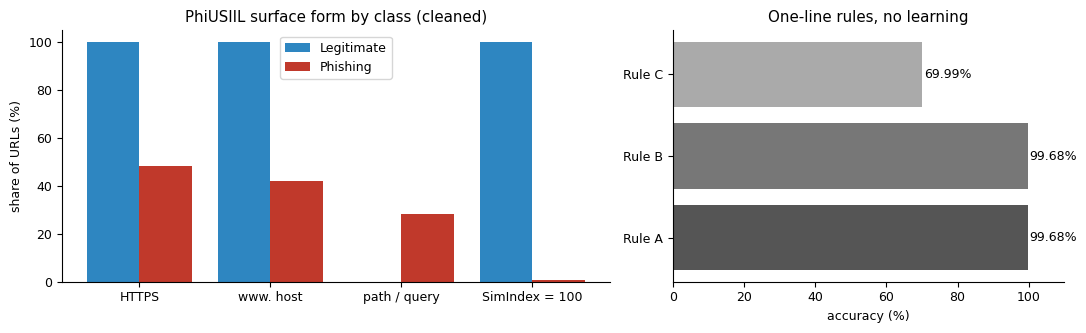

figure: fig_audit_surface.pdf


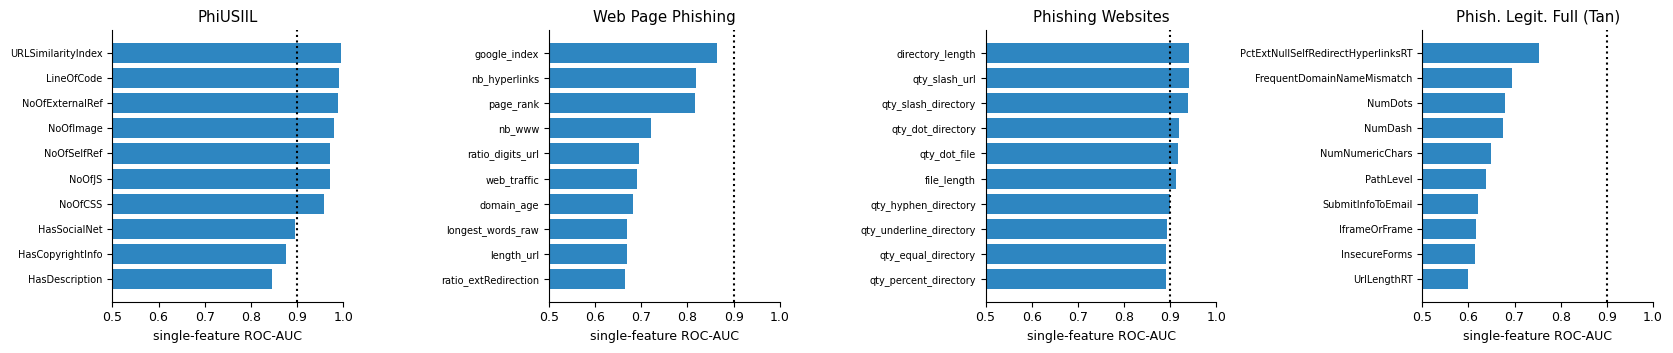

figure: fig_univariate_auc.pdf


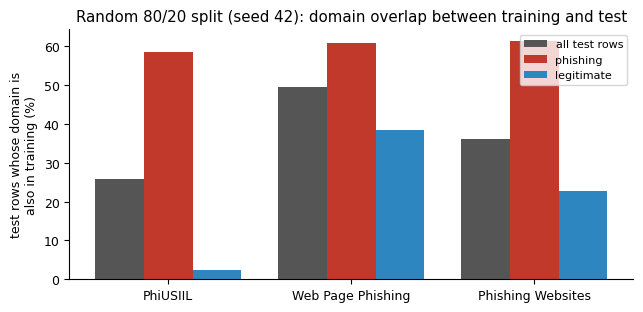

figure: fig_overlap.pdf


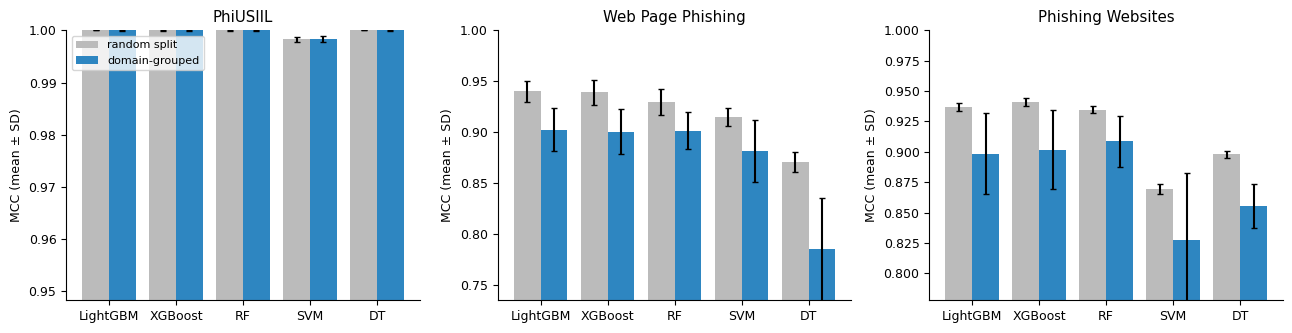

figure: fig_split_effect.pdf


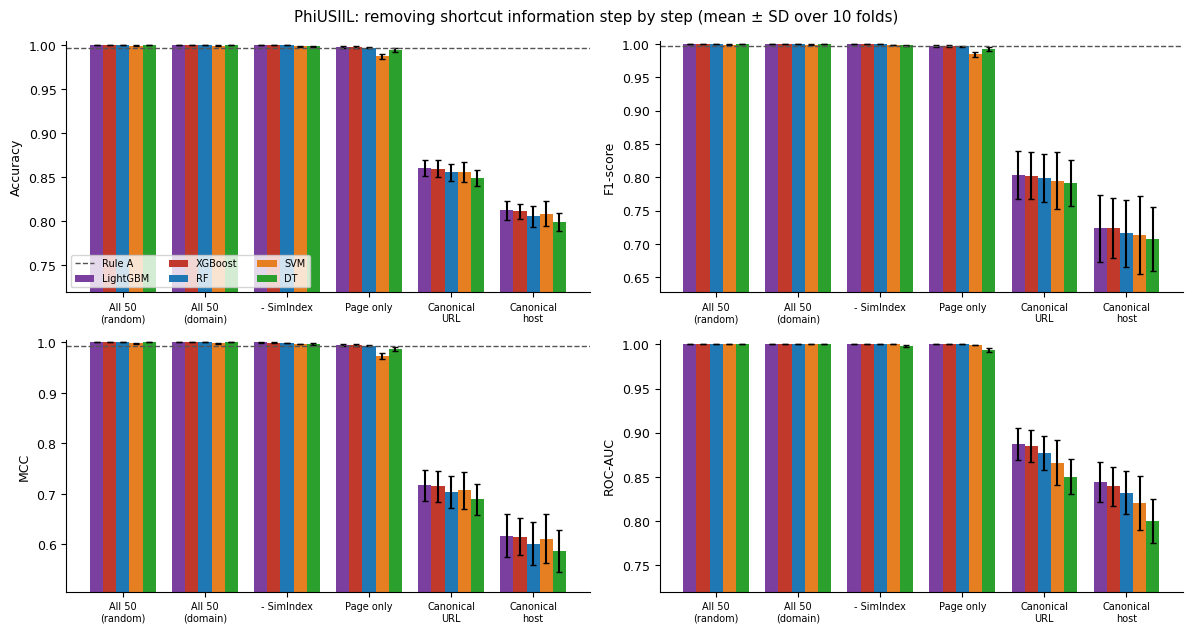

figure: fig_shortcut_ladder.pdf


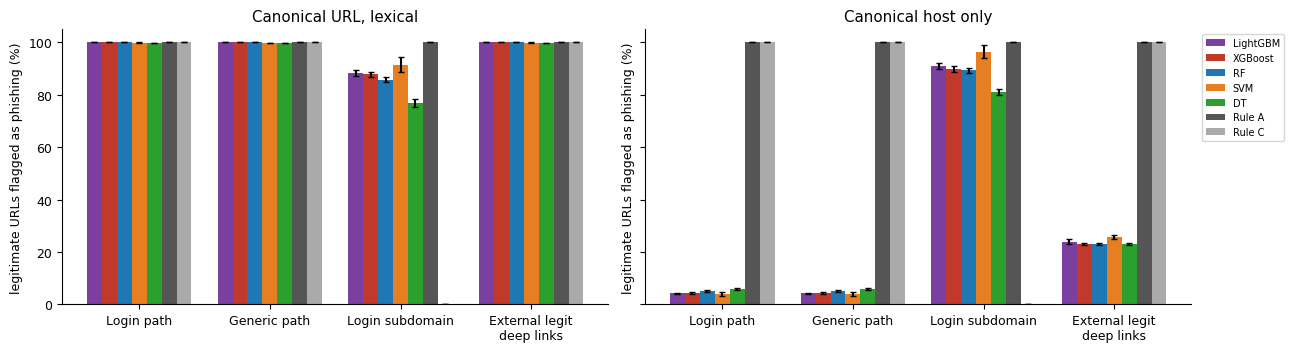

figure: fig_deeplink_fpr.pdf


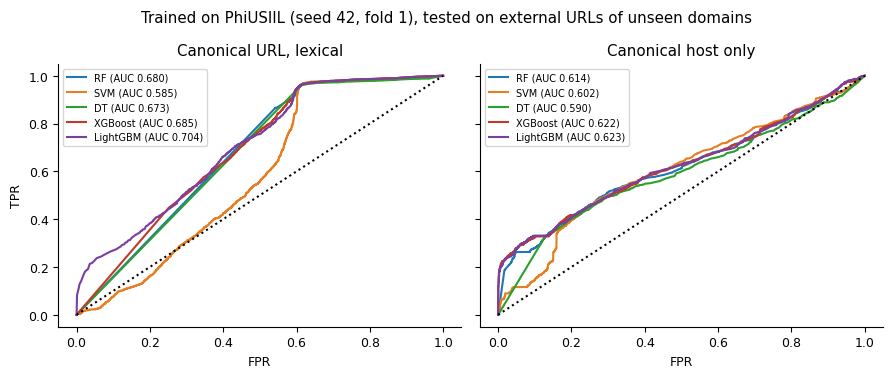

figure: fig_external_roc.pdf


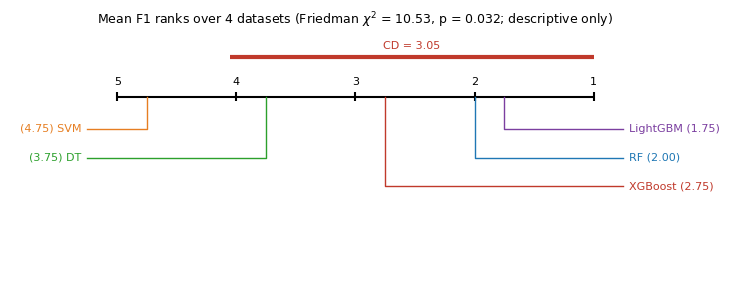

figure: fig_cd_diagram.pdf


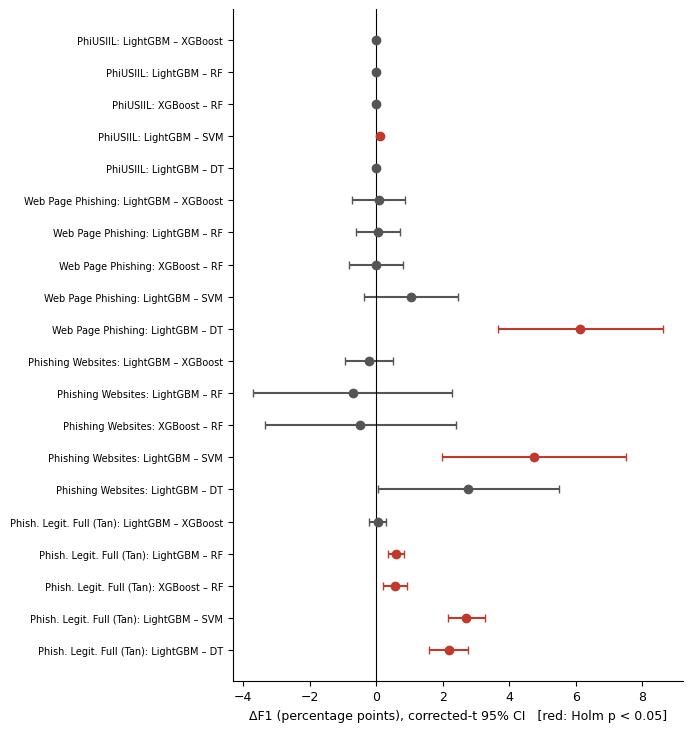

figure: fig_forest_paired.pdf


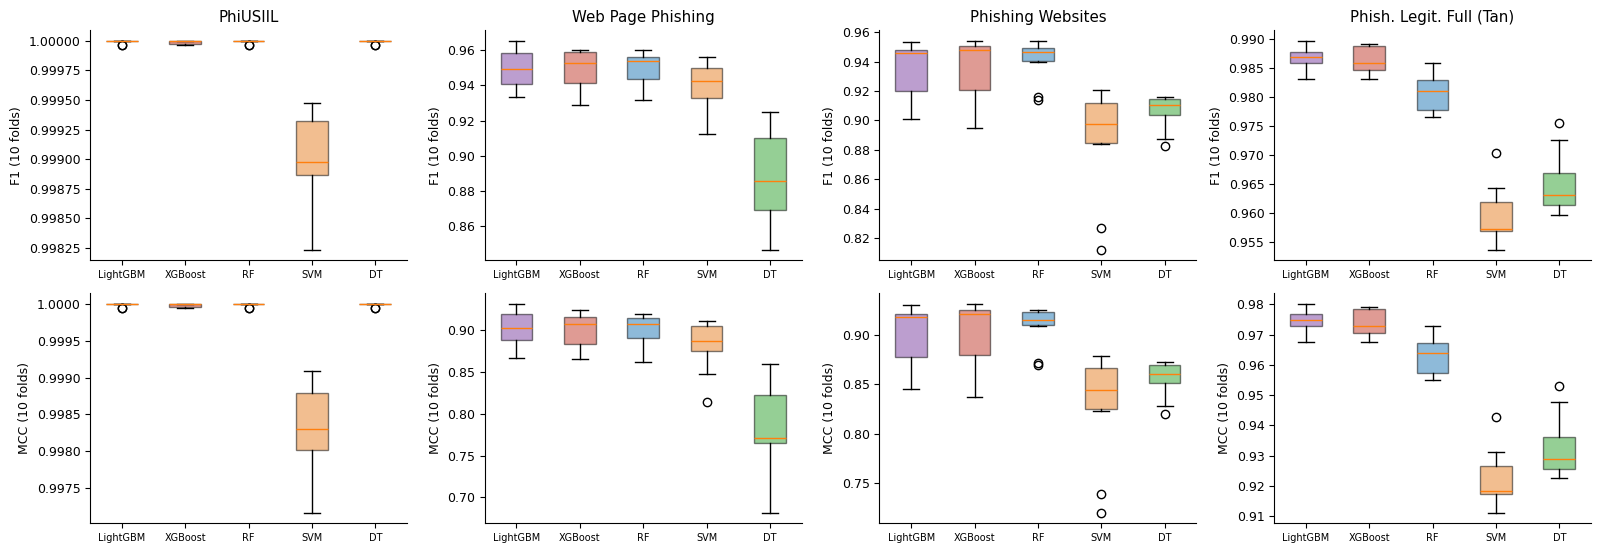

figure: fig_cv_boxplots.pdf


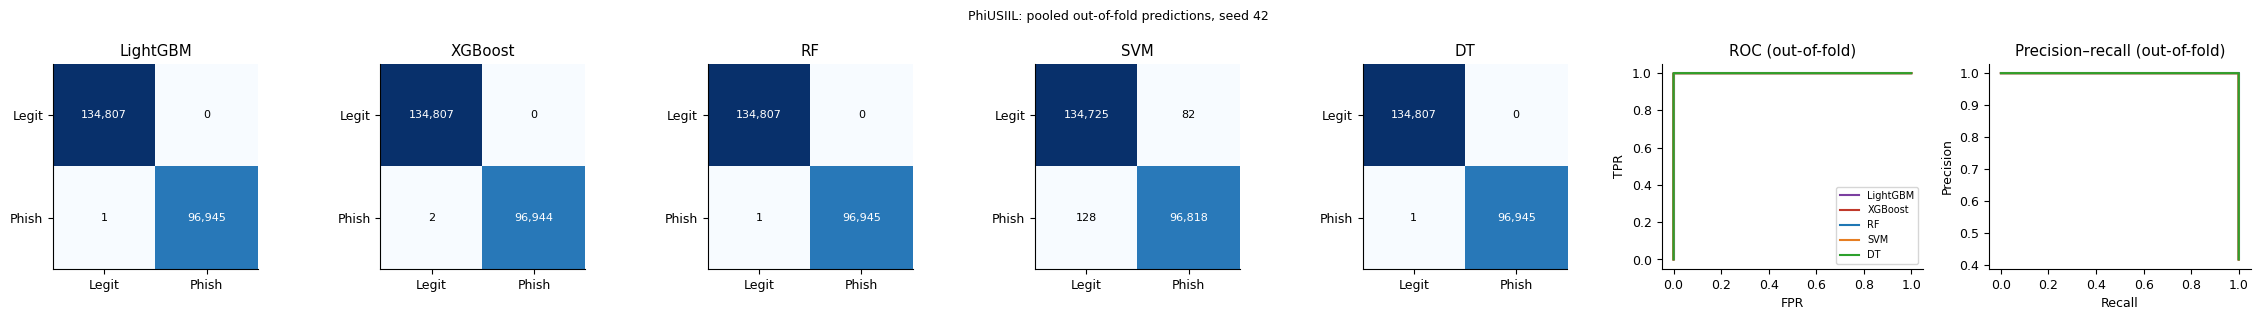

figure: fig_oof_PhiUSIIL.pdf


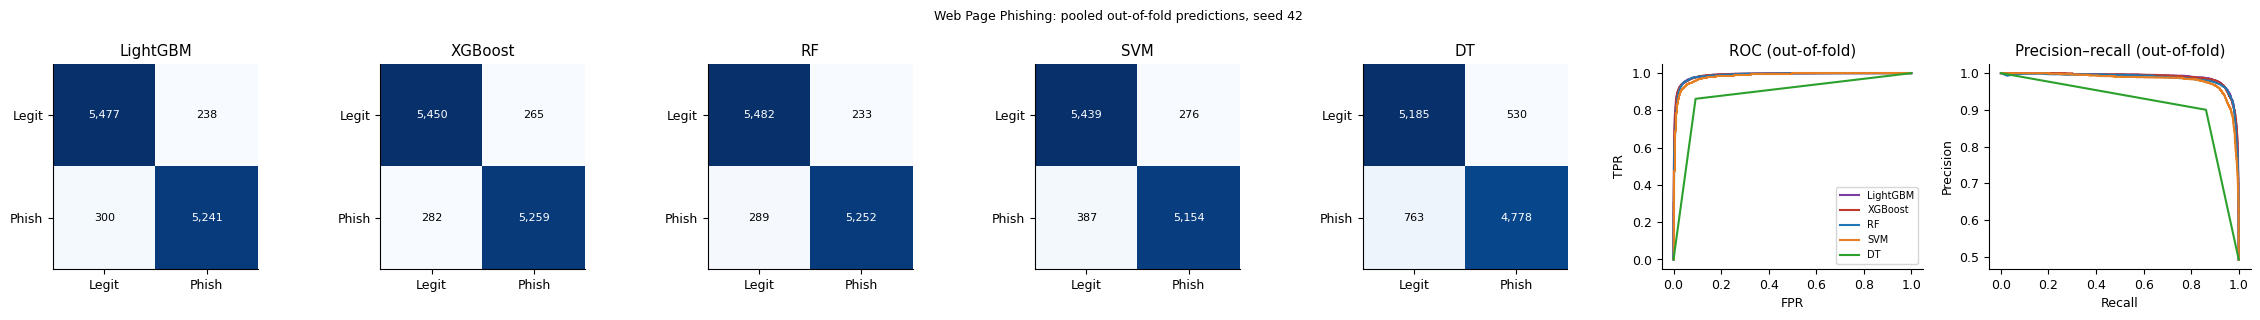

figure: fig_oof_WebPage.pdf


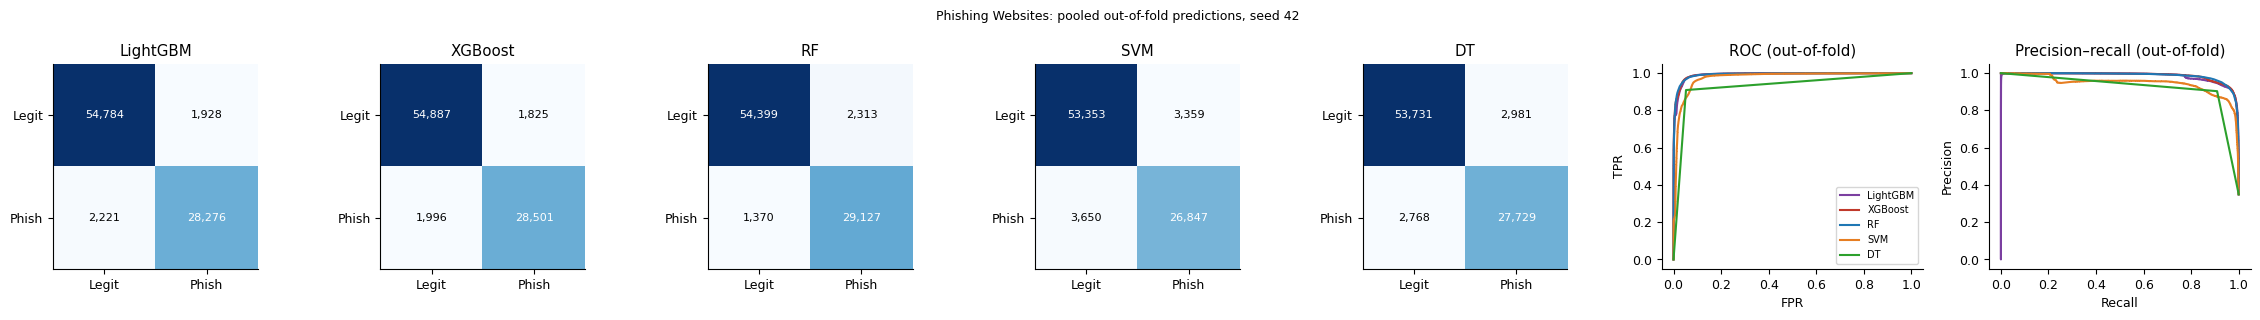

figure: fig_oof_PhishWeb.pdf


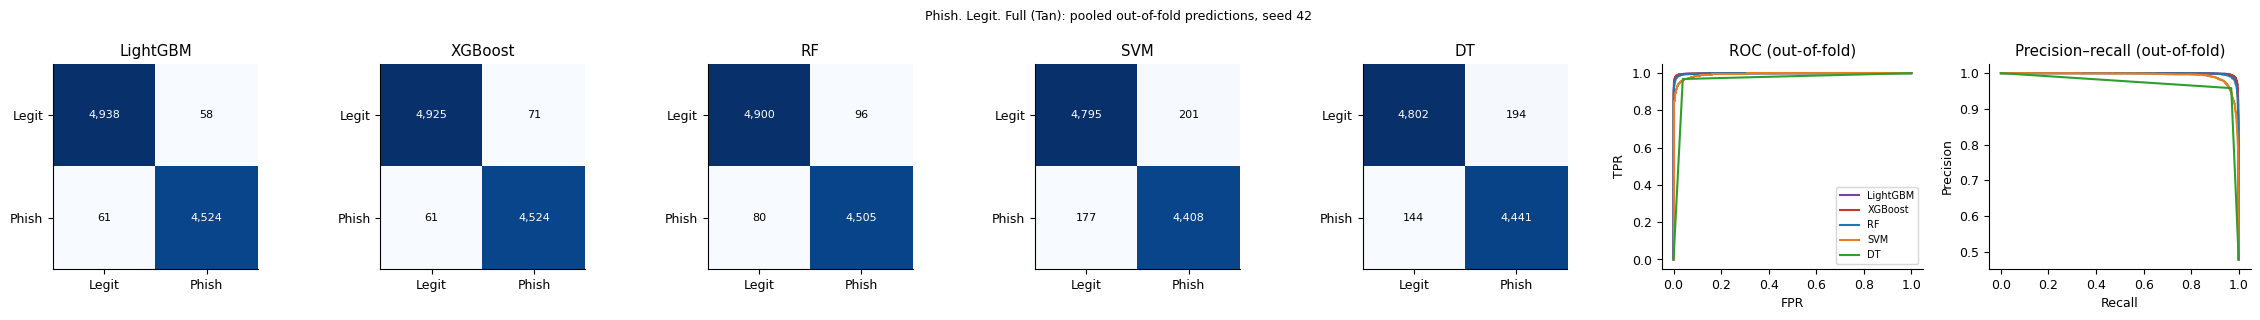

figure: fig_oof_Tan.pdf


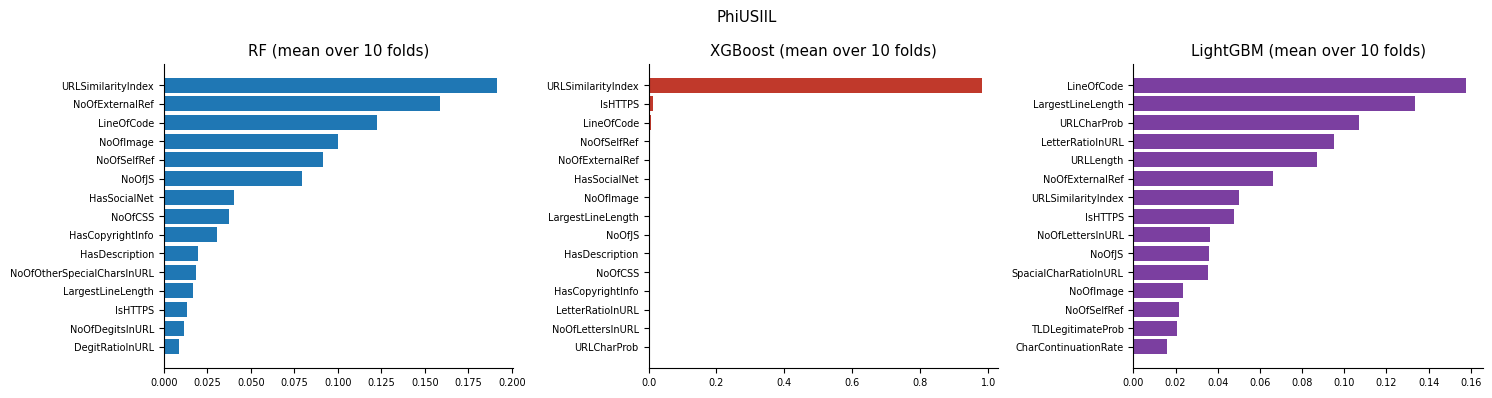

figure: fig_importance_PhiUSIIL.pdf


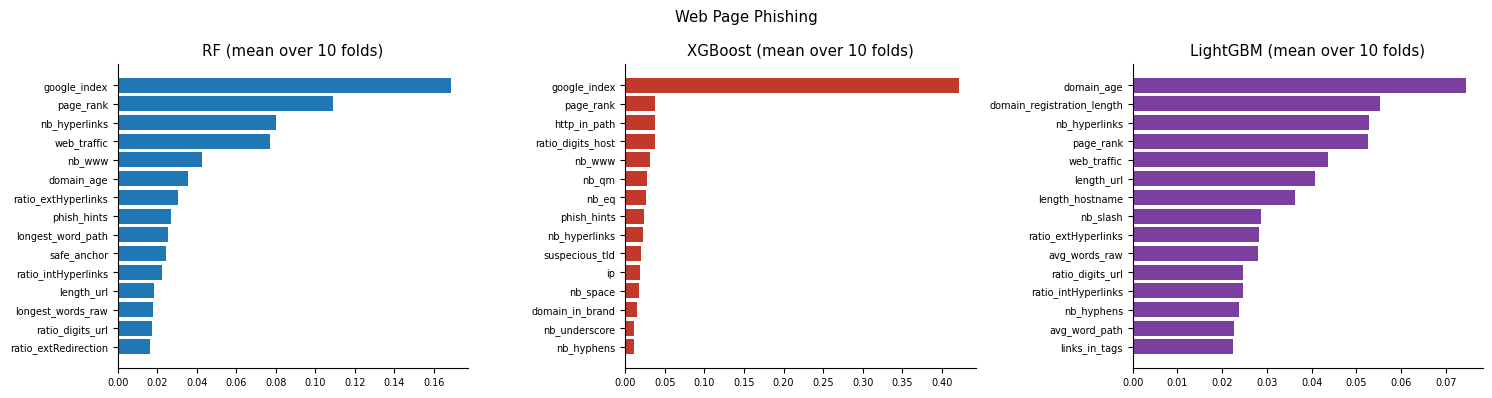

figure: fig_importance_WebPage.pdf


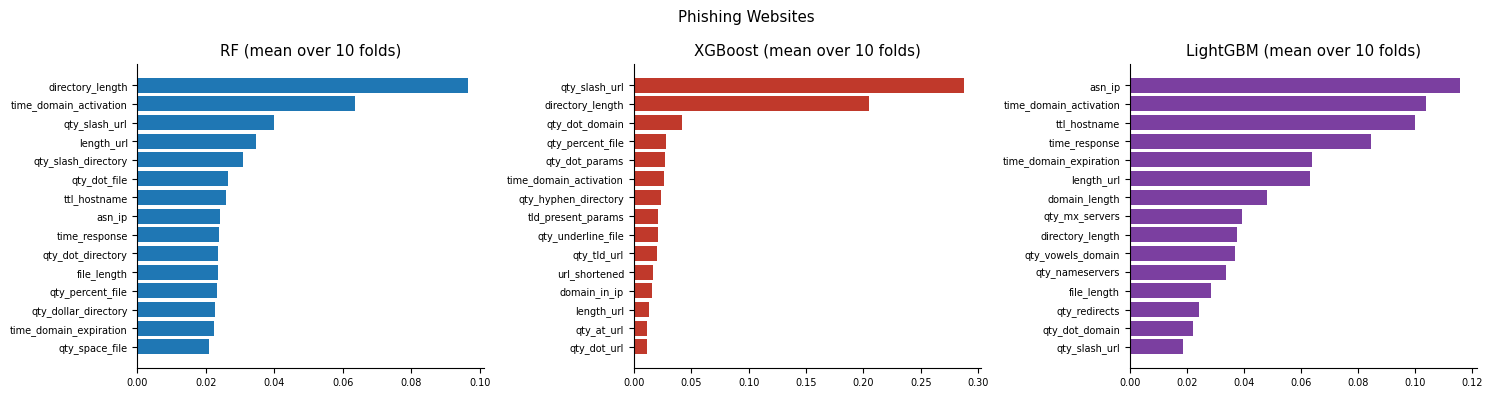

figure: fig_importance_PhishWeb.pdf


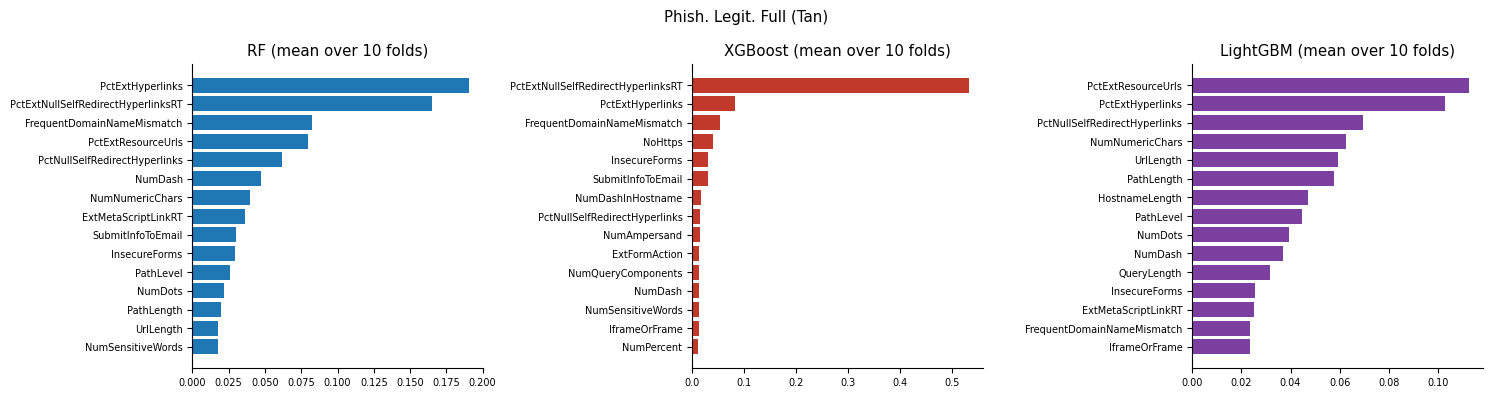

figure: fig_importance_Tan.pdf


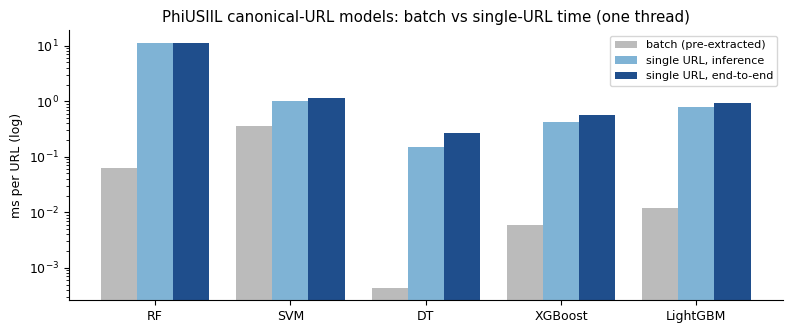

figure: fig_latency.pdf


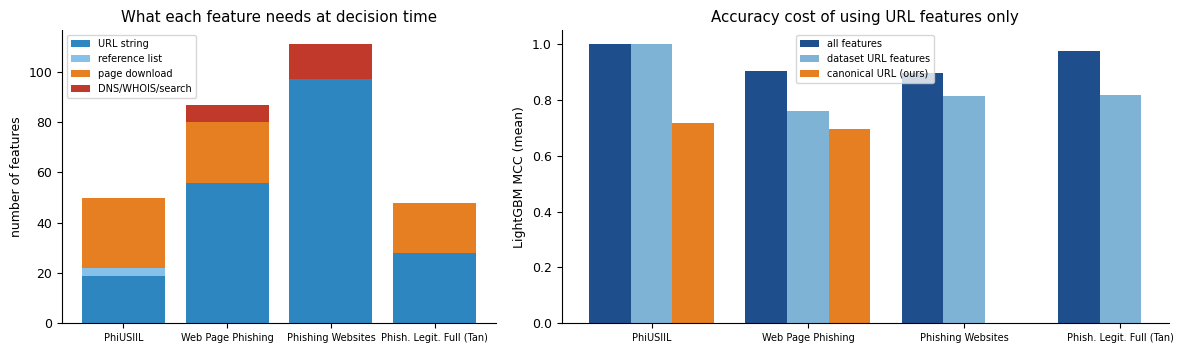

figure: fig_availability.pdf


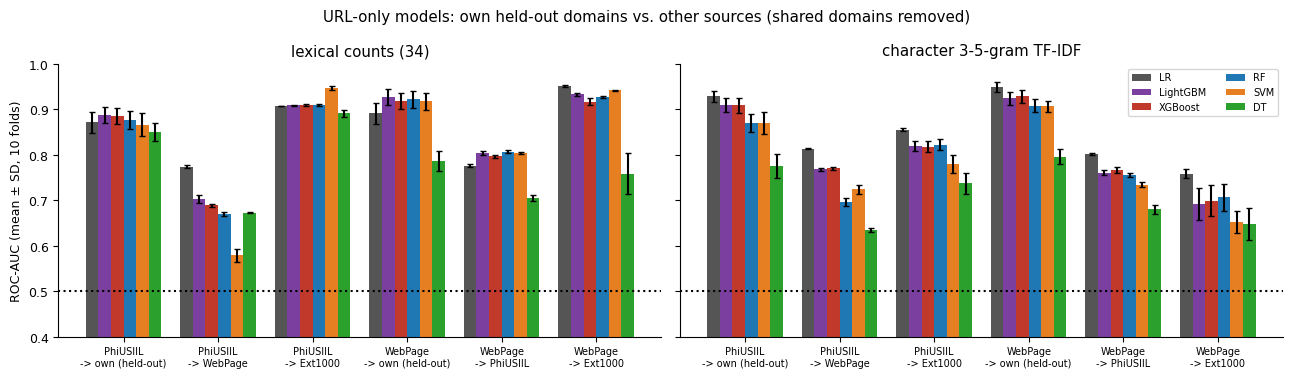

figure: fig_urlext.pdf


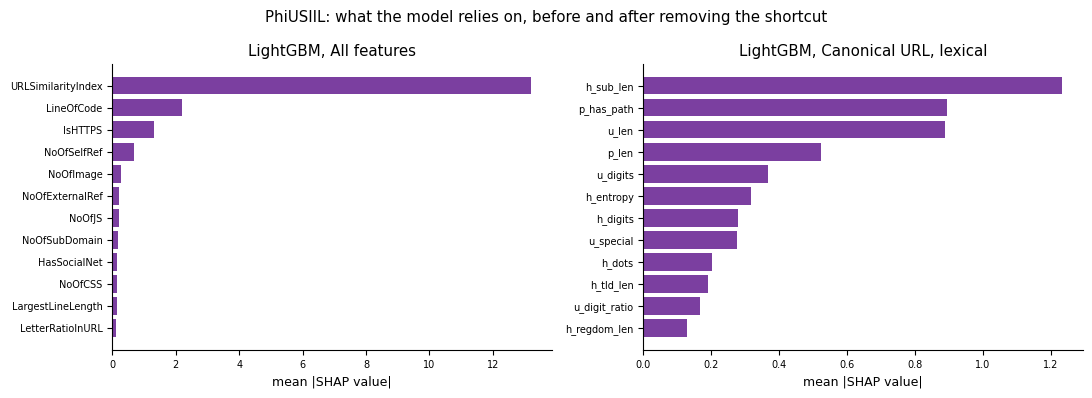

figure: fig_shap_phiusiil.pdf


In [17]:
# ===================== 13b. Figures =====================
COL = {"LightGBM": "#7b3fa0", "XGBoost": "#c0392b", "RF": "#1f77b4", "SVM": "#e67e22", "DT": "#2ca02c",
       "Rule A (https://www. homepage)": "#555555", "Rule C (canonical homepage)": "#aaaaaa"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIG(name), bbox_inches="tight")
    if PLATFORM != "local":
        plt.show()
    plt.close(fig); print("figure:", name)

def safe(fn):
    try:
        fn()
    except Exception as e:                                   # one failing figure must not stop the run
        print("figure skipped:", fn.__name__, "->", repr(e))

def grouped_bars(ax, groups, series, values, errs=None, colors=None, width=None):
    n = len(series); width = width or 0.8 / n
    for j, sname in enumerate(series):
        ax.bar(np.arange(len(groups)) + (j - (n - 1) / 2) * width, values[j], width,
               yerr=None if errs is None else errs[j], capsize=2, label=sname,
               color=None if colors is None else colors.get(sname))
    ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups)

def fig_audit():
    props = ["https (%)", "host www. (%)", "path/query (%)", "SimIndex=100 (%)"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
    grouped_bars(ax[0], ["HTTPS", "www. host", "path / query", "SimIndex = 100"], ["Legitimate", "Phishing"],
                 [surf.set_index("Class").loc[c, props].values for c in ["Legitimate", "Phishing"]],
                 colors={"Legitimate": "#2e86c1", "Phishing": "#c0392b"})
    ax[0].set_ylabel("share of URLs (%)"); ax[0].legend(); ax[0].set_title("PhiUSIIL surface form by class (cleaned)")
    ax[1].barh([r.split(":")[0] for r in rule_tab.Rule], 100 * rule_tab.Accuracy, color=["#555", "#777", "#aaa"])
    for i, v in enumerate(100 * rule_tab.Accuracy):
        ax[1].text(v + 0.5, i, f"{v:.2f}%", va="center")
    ax[1].set_xlim(0, 110); ax[1].set_xlabel("accuracy (%)"); ax[1].set_title("One-line rules, no learning")
    savefig(fig, "fig_audit_surface.pdf")

def fig_univariate():
    fig, ax = plt.subplots(1, len(DS), figsize=(4.2 * len(DS), 3.6))
    for a_, (k, d) in zip(ax, DS.items()):
        X = d["X"][d["fsets"]["Full"]]
        auc = pd.Series({c: folded_auc(d["y"], X[c].values) for c in X.columns}).sort_values().tail(10)
        a_.barh(auc.index, auc.values, color="#2e86c1"); a_.axvline(0.9, ls=":", c="k")
        a_.set_xlim(0.5, 1.0); a_.set_title(DS_LABEL[k]); a_.tick_params(axis="y", labelsize=7)
        a_.set_xlabel("single-feature ROC-AUC")
    savefig(fig, "fig_univariate_auc.pdf")

def fig_overlap():
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    grouped_bars(ax, list(ov.Dataset), ["all test rows", "phishing", "legitimate"],
                 [ov["Test rows sharing a group (%)"], ov["  phishing (%)"], ov["  legitimate (%)"]],
                 colors={"all test rows": "#555", "phishing": "#c0392b", "legitimate": "#2e86c1"})
    ax.set_ylabel("test rows whose domain is\nalso in training (%)"); ax.legend(fontsize=8)
    ax.set_title("Random 80/20 split (seed 42): domain overlap between training and test")
    savefig(fig, "fig_overlap.pdf")

def fig_split_effect():
    sets = {"PhiUSIIL": (R[(R.exp == "shortcut") & (R.fs == "Full") & (R.split == "random")],
                         R[(R.exp == "main") & (R.dataset == "PhiUSIIL")])}
    for k in ["WebPage", "PhishWeb"]:
        sets[k] = (R[(R.exp == "randomsplit") & (R.dataset == k)], R[(R.exp == "main") & (R.dataset == k)])
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
    for a_, (k, (rnd, grp)) in zip(ax, sets.items()):
        vals = [[g[g.model == m].MCC.mean() for m in MODEL_ORDER] for g in (rnd, grp)]
        errs = [[g[g.model == m].MCC.std(ddof=1) for m in MODEL_ORDER] for g in (rnd, grp)]
        grouped_bars(a_, MODEL_ORDER, ["random split", "domain-grouped"], vals, errs,
                     colors={"random split": "#bbbbbb", "domain-grouped": "#2e86c1"})
        lo = np.nanmin(vals) - 0.05
        a_.set_ylim(max(0, lo), 1.0); a_.set_title(DS_LABEL[k]); a_.set_ylabel("MCC (mean ± SD)")
    ax[0].legend(fontsize=8)
    savefig(fig, "fig_split_effect.pdf")

def fig_ladder():
    labels = ["All 50\n(random)", "All 50\n(domain)", "- SimIndex", "Page only", "Canonical\nURL", "Canonical\nhost"]
    fig, ax = plt.subplots(2, 2, figsize=(12, 6.4))
    for a_, (met, name) in zip(ax.ravel(), [("Acc", "Accuracy"), ("F1", "F1-score"), ("MCC", "MCC"), ("AUC", "ROC-AUC")]):
        vals = [[S[(S.fs == f) & (S.split == sp) & (S.model == m)][met].mean() for f, sp in LADDER] for m in MODEL_ORDER]
        errs = [[S[(S.fs == f) & (S.split == sp) & (S.model == m)][met].std(ddof=1) for f, sp in LADDER] for m in MODEL_ORDER]
        grouped_bars(a_, labels, MODEL_ORDER, vals, errs, COL)
        if len(E) and met in ("Acc", "F1", "MCC"):
            RS = E[(E["exp"] == "shortcut") & (E["fs"] == "Full") & (E.model == RULES[0])]
            a_.axhline(RS[met].mean(), ls="--", c="#555", lw=1, label="Rule A")
        a_.set_ylim(max(0, np.nanmin(vals) - 0.08), 1.005); a_.set_ylabel(name); a_.tick_params(axis="x", labelsize=7)
    ax[0, 0].legend(ncol=3, fontsize=7, loc="lower left")
    fig.suptitle("PhiUSIIL: removing shortcut information step by step (mean ± SD over 10 folds)")
    savefig(fig, "fig_shortcut_ladder.pdf")

def fig_deeplink():
    tests = ["Login path", "Generic path", "Login subdomain"]
    names = MODEL_ORDER + ["Rule A (https://www. homepage)", "Rule C (canonical homepage)"]
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
    for a_, fs in zip(ax, ["CanonURL", "CanonHost"]):
        vals, errs = [], []
        for m in names:
            v = [100 * DL[(DL.fs == fs) & (DL.model == m) & (DL.test == t)].FPR.mean() for t in tests]
            e = [100 * DL[(DL.fs == fs) & (DL.model == m) & (DL.test == t)].FPR.std(ddof=1) for t in tests]
            x = EX[(EX.fs == fs) & (EX.model == m)]
            v.append(100 * x["FPR legit deep links"].mean()); e.append(100 * x["FPR legit deep links"].std(ddof=1))
            vals.append(v); errs.append(e)
        grouped_bars(a_, tests + ["External legit\ndeep links"], [n.split(" (")[0] for n in names], vals, errs,
                     {n.split(" (")[0]: COL[n] for n in names})
        a_.set_title(FS_TEX[fs].replace("\\texttt{", "").replace("}", "")); a_.set_ylabel("legitimate URLs flagged as phishing (%)")
    ax[1].legend(ncol=1, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
    savefig(fig, "fig_deeplink_fpr.pdf")

def fig_external_roc():
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
    for a_, fs in zip(ax, ["CanonURL", "CanonHost"]):
        for r in [r for r in EXT_SCORES if r["fs"] == fs and r["model"] in MODEL_ORDER]:
            f_, t_, _ = roc_curve(EXT["y"], r["scores"])
            a_.plot(f_, t_, color=COL[r["model"]], label=f"{r['model']} (AUC {roc_auc_score(EXT['y'], r['scores']):.3f})")
        a_.plot([0, 1], [0, 1], ":", c="k"); a_.set(xlabel="FPR", title=FS_TEX[fs]); a_.legend(fontsize=7)
    ax[0].set_ylabel("TPR")
    fig.suptitle("Trained on PhiUSIIL (seed 42, fold 1), tested on external URLs of unseen domains")
    savefig(fig, "fig_external_roc.pdf")

def fig_cd():
    """Critical-difference diagram (Demsar 2006) of the mean F1 ranks over the four datasets."""
    if not fried:
        return
    ranks = sorted(fried["mean_ranks"].items(), key=lambda x: x[1]); cd = fried["nemenyi_CD"]; k = len(ranks)
    fig, ax = plt.subplots(figsize=(7.5, 2.9))
    ax.set_xlim(k + 0.9, 0.1); ax.set_ylim(-0.1, 1.35); ax.axis("off")
    ax.hlines(1.0, 1, k, color="k")
    for i in range(1, k + 1):
        ax.vlines(i, 0.97, 1.03, color="k"); ax.text(i, 1.07, str(i), ha="center", fontsize=8)
    half = (k + 1) // 2
    for j, (m, r) in enumerate(ranks):
        c = COL.get(m, "k")
        if j < half:                                   # better half: labels on the right
            y = 0.8 - 0.18 * j; ax.plot([r, r, 0.75], [1.0, y, y], c=c, lw=1)
            ax.text(0.7, y, f"{m} ({r:.2f})", ha="left", va="center", fontsize=8, color=c)
        else:                                          # worse half: labels on the left
            y = 0.8 - 0.18 * (k - 1 - j); ax.plot([r, r, k + 0.25], [1.0, y, y], c=c, lw=1)
            ax.text(k + 0.3, y, f"({r:.2f}) {m}", ha="right", va="center", fontsize=8, color=c)
    ax.hlines(1.25, 1, 1 + cd, color="#c0392b", lw=3)
    ax.text(1 + cd / 2, 1.3, f"CD = {cd:.2f}", ha="center", color="#c0392b", fontsize=8)
    ax.set_title(f"Mean F1 ranks over 4 datasets (Friedman $\\chi^2$ = {fried['chi2']:.2f}, p = {fried['p']:.3f}; "
                 f"descriptive only)", fontsize=9, pad=12)
    savefig(fig, "fig_cd_diagram.pdf")

def fig_forest():
    g = PR[PR.exp == "main"].copy()
    g["o"] = g.dataset.map({k: i for i, k in enumerate(DS)}); g = g.sort_values(["o"], kind="stable").reset_index(drop=True)
    if not len(g):
        return
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(g) + 1))
    for i, r in g.iterrows():
        sig = r.p_F1_holm < 0.05
        ax.errorbar(100 * r.dF1, i, xerr=[[100 * (r.dF1 - r.dF1_lo)], [100 * (r.dF1_hi - r.dF1)]], fmt="o",
                    color="#c0392b" if sig else "#555", capsize=3)
    ax.axvline(0, c="k", lw=0.8)
    ax.set_yticks(range(len(g))); ax.set_yticklabels([f"{DS_LABEL[r.dataset]}: {r.A} – {r.B}" for _, r in g.iterrows()], fontsize=7)
    ax.invert_yaxis(); ax.set_xlabel("ΔF1 (percentage points), corrected-t 95% CI   [red: Holm p < 0.05]")
    savefig(fig, "fig_forest_paired.pdf")

def fig_box():
    main = R[R.exp == "main"]
    fig, ax = plt.subplots(2, len(DS), figsize=(4 * len(DS), 5.6))
    for row, met in enumerate(["F1", "MCC"]):
        for a_, ds in zip(ax[row], DS):
            g = main[main.dataset == ds]
            bp = a_.boxplot([g[g.model == m][met].values for m in MODEL_ORDER], patch_artist=True)
            for patch, m in zip(bp["boxes"], MODEL_ORDER):
                patch.set_facecolor(COL[m]); patch.set_alpha(0.5)
            a_.set_xticks(range(1, 6)); a_.set_xticklabels(MODEL_ORDER, fontsize=7)
            a_.set_title(DS_LABEL[ds] if row == 0 else ""); a_.set_ylabel(f"{met} (10 folds)")
    savefig(fig, "fig_cv_boxplots.pdf")

def fig_oof():
    for ds in DS:
        parts = [o for key, o in CK["oof"] if key[0] == "main" and key[1] == ds and key[4] == "s42"]
        if not parts:
            continue
        yy = np.concatenate([o["y"] for o in parts])
        fig, ax = plt.subplots(1, 7, figsize=(23, 3.2))
        for a_, m in zip(ax[:5], MODEL_ORDER):
            cm = confusion_matrix(yy, np.concatenate([o[m][0] for o in parts]))
            a_.imshow(cm, cmap="Blues")
            for (i, j), v in np.ndenumerate(cm):
                a_.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8, color="white" if v > cm.max() / 2 else "k")
            a_.set(title=m, xticks=[0, 1], yticks=[0, 1], xticklabels=["Legit", "Phish"], yticklabels=["Legit", "Phish"])
        for m in MODEL_ORDER:
            sc = np.concatenate([o[m][1] for o in parts])
            f_, t_, _ = roc_curve(yy, sc); ax[5].plot(f_, t_, color=COL[m], label=m)
            p_, r_, _ = precision_recall_curve(yy, sc); ax[6].plot(r_, p_, color=COL[m], label=m)
        ax[5].set(xlabel="FPR", ylabel="TPR", title="ROC (out-of-fold)"); ax[5].legend(fontsize=7)
        ax[6].set(xlabel="Recall", ylabel="Precision", title="Precision–recall (out-of-fold)")
        fig.suptitle(f"{DS_LABEL[ds]}: pooled out-of-fold predictions, seed 42", fontsize=9)
        savefig(fig, f"fig_oof_{ds}.pdf")

def fig_importance():
    for ds in DS:
        imps = {m: [i[m] for key, i in CK["imp"] if key[0] == "main" and key[1] == ds and m in i]
                for m in ["RF", "XGBoost", "LightGBM"]}
        have = [m for m in imps if imps[m]]
        if not have:
            continue
        fig, ax = plt.subplots(1, len(have), figsize=(5 * len(have), 4), squeeze=False)
        for a_, m in zip(ax[0], have):
            s_ = pd.concat(imps[m], axis=1).mean(axis=1)
            s_ = (s_ / s_.sum()).sort_values().tail(15)
            a_.barh(s_.index, s_.values, color=COL[m]); a_.set_title(f"{m} (mean over 10 folds)"); a_.tick_params(labelsize=7)
        fig.suptitle(DS_LABEL[ds]); savefig(fig, f"fig_importance_{ds}.pdf")

def fig_latency():
    fig, ax = plt.subplots(figsize=(8, 3.4))
    cols = ["Batch inference (ms/URL)", "Single-URL inference, median (ms)", "Single-URL end-to-end, median (ms)"]
    grouped_bars(ax, list(lat.Model), ["batch (pre-extracted)", "single URL, inference", "single URL, end-to-end"],
                 [lat[c].values for c in cols], colors={"batch (pre-extracted)": "#bbb", "single URL, inference": "#7fb3d5",
                                                       "single URL, end-to-end": "#1f4e8c"})
    ax.set_yscale("log"); ax.set_ylabel("ms per URL (log)"); ax.legend(fontsize=8)
    ax.set_title("PhiUSIIL canonical-URL models: batch vs single-URL time (one thread)")
    savefig(fig, "fig_latency.pdf")

def fig_availability():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
    names = ["URL string", "reference list", "page download", "DNS/WHOIS/search"]
    bottom = np.zeros(len(DS))
    for i, (n, c) in enumerate(zip(names, ["#2e86c1", "#85c1e9", "#e67e22", "#c0392b"])):
        v = np.array([AVAIL[k][i] for k in DS]); ax[0].bar([DS_LABEL[k] for k in DS], v, bottom=bottom, label=n, color=c)
        bottom += v
    ax[0].set_ylabel("number of features"); ax[0].legend(fontsize=7); ax[0].tick_params(axis="x", labelsize=7)
    ax[0].set_title("What each feature needs at decision time")
    sets = {"PhiUSIIL": [("main", "Full"), ("avail", "DatasetURL"), ("shortcut", "CanonURL")],
            "WebPage": [("main", "Full"), ("avail", "DatasetURL"), ("avail", "CanonURL")],
            "PhishWeb": [("main", "Full"), ("avail", "DatasetURL")], "Tan": [("main", "Full"), ("avail", "DatasetURL")]}
    lab = {"Full": "all features", "DatasetURL": "dataset URL features", "CanonURL": "canonical URL (ours)"}
    vals = {l: [] for l in lab.values()}
    for k in DS:
        have = dict((fs, ex) for ex, fs in sets[k])
        for fs, l in lab.items():
            g = R[(R.exp == have.get(fs, "-")) & (R.dataset == k) & (R.fs == fs) & (R.model == "LightGBM") & (R.split == split_of(k))]
            vals[l].append(g.MCC.mean() if len(g) else np.nan)
    grouped_bars(ax[1], [DS_LABEL[k] for k in DS], list(vals), [vals[l] for l in vals],
                 colors={"all features": "#1f4e8c", "dataset URL features": "#7fb3d5", "canonical URL (ours)": "#e67e22"})
    ax[1].set_ylabel("LightGBM MCC (mean)"); ax[1].legend(fontsize=7); ax[1].tick_params(axis="x", labelsize=7)
    ax[1].set_title("Accuracy cost of using URL features only")
    savefig(fig, "fig_availability.pdf")

def fig_urlext():
    U = E[(E.exp == "urlext") & ~E.test.str.startswith("variant")]
    if not len(U):
        return
    pairs = [(s_, t) for s_ in TRAIN_SOURCES for t in ["held-out fold"] + [x for x in URLSRC if x != s_]]
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
    for a_, view in zip(ax, ["CanonURL", "CharNgram"]):
        names = ["LR"] + MODEL_ORDER
        vals = [[U[(U.dataset == s_) & (U.test == t) & (U.fs == view) & (U.model == m)].AUC.mean() for s_, t in pairs] for m in names]
        errs = [[U[(U.dataset == s_) & (U.test == t) & (U.fs == view) & (U.model == m)].AUC.std(ddof=1) for s_, t in pairs] for m in names]
        grouped_bars(a_, [f"{s_}\n-> {'own (held-out)' if t == 'held-out fold' else t}" for s_, t in pairs], names, vals, errs,
                     {**COL, "LR": "#555555"})
        a_.axhline(0.5, ls=":", c="k"); a_.set_ylim(0.4, 1.0); a_.tick_params(axis="x", labelsize=7)
        a_.set_title("lexical counts (34)" if view == "CanonURL" else "character 3-5-gram TF-IDF")
    ax[0].set_ylabel("ROC-AUC (mean ± SD, 10 folds)"); ax[1].legend(ncol=2, fontsize=7)
    fig.suptitle("URL-only models: own held-out domains vs. other sources (shared domains removed)")
    savefig(fig, "fig_urlext.pdf")

def fig_shap():
    import shap
    if not HAVE_LGBM:
        return
    P = DS["PhiUSIIL"]; tr, te = cv_splits(P["y"], P["groups"], "grouped", 42)[0]
    rs = np.random.RandomState(42); te_s = rs.choice(te, min(2000, len(te)), replace=False)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a_, fs in zip(ax, ["Full", "CanonURL"]):
        cols = P["fsets"][fs]; X = P["X"][cols].values
        mdl = make_model("LightGBM", 42).fit(X[tr], P["y"][tr])
        sv = shap.TreeExplainer(mdl).shap_values(X[te_s])
        sv = sv[1] if isinstance(sv, list) else sv
        imp = pd.Series(np.abs(sv).mean(axis=0), index=cols).sort_values().tail(12)
        a_.barh(imp.index, imp.values, color="#7b3fa0"); a_.set_title(f"LightGBM, {FS_TEX[fs]}")
        a_.set_xlabel("mean |SHAP value|"); a_.tick_params(labelsize=7)
    fig.suptitle("PhiUSIIL: what the model relies on, before and after removing the shortcut")
    savefig(fig, "fig_shap_phiusiil.pdf")

if RUN["stats"]:
    for fn in [fig_audit, fig_univariate, fig_overlap, fig_split_effect, fig_ladder, fig_deeplink, fig_external_roc,
               fig_cd, fig_forest, fig_box, fig_oof, fig_importance, fig_latency, fig_availability, fig_urlext, fig_shap]:
        safe(fn)

In [18]:
# ===================== 14. Package everything =====================
zpath = os.path.join(OUT_DIR, "revision_outputs.zip")
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for sub in ["tables", "figures", "repro"]:
        for f in glob.glob(os.path.join(OUT_DIR, sub, "*")):
            z.write(f, os.path.join(sub, os.path.basename(f)))
print("All outputs:", zpath)
if IN_COLAB:
    from google.colab import files
    files.download(zpath)

All outputs: /kaggle/working/revision_results/revision_outputs.zip
